# Imports

In [2]:
import pandas as pd
import numpy as np
import json
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb as db

# Show every single column
pd.set_option('display.max_columns', None)

# Creating dataset for analysis

#### Creating dataframe containing ball-to-ball data

In [3]:
folder_path = Path("/Users/akrohit/Desktop/Learning/Cricket Bowler Average Attribution/all_male_json")

all_deliveries = []

for file_path in folder_path.glob("*.json"):
    with open(file_path, "r") as f:
        match_data = json.load(f)

    match_id = file_path.stem
    info = match_data.get("info", {})

    # NEW: name -> identifier lookup for this match
    registry = info.get("registry", {}).get("people", {})

    for innings_num, innings in enumerate(match_data.get("innings", []), start=1):
        batting_team = innings.get("team")

        for over in innings.get("overs", []):
            over_num = over.get("over")

            for ball_num, delivery in enumerate(over.get("deliveries", []), start=1):
                batter = delivery.get("batter")
                bowler = delivery.get("bowler")
                non_striker = delivery.get("non_striker")

                row = {
                    "match_id": match_id,
                    "gender": info.get("gender"),   # NEW
                    "teams": info.get("teams"),   # NEW — list of both team names, e.g. ["England", "Pakistan"]
                    "team_type": info.get("team_type"),   # NEW — "international" or "club"
                    "innings": innings_num,
                    "date": info.get("dates", [None])[0],
                    "venue": info.get("venue"),
                    "neutral_venue": bool(info.get("neutral_venue", False)),
                    "batting_team": batting_team,
                    "over": over_num,
                    "ball": ball_num,
                    "batter": batter,
                    "bowler": bowler,
                    "non_striker": non_striker,
                    # NEW: identifiers, looked up from the registry
                    "batter_id": registry.get(batter),
                    "bowler_id": registry.get(bowler),
                    "non_striker_id": registry.get(non_striker),
                    "runs_batter": delivery.get("runs", {}).get("batter"),
                    "runs_extras": delivery.get("runs", {}).get("extras"),
                    "runs_total": delivery.get("runs", {}).get("total"),
                }

                extras_detail = delivery.get("extras", {})   # NEW
                row["wides"] = extras_detail.get("wides", 0)      # NEW
                row["noballs"] = extras_detail.get("noballs", 0)  # NEW
                row["byes"] = extras_detail.get("byes", 0)        # NEW
                row["legbyes"] = extras_detail.get("legbyes", 0)  # NEW
                row["penalty"] = extras_detail.get("penalty", 0)  # NEW

                wickets = delivery.get("wickets", [])
                if wickets:
                    player_out = wickets[0].get("player_out")
                    row["wicket_kind"] = wickets[0].get("kind")
                    row["player_out"] = player_out
                    row["player_out_id"] = registry.get(player_out)  # NEW
                else:
                    row["wicket_kind"] = None
                    row["player_out"] = None
                    row["player_out_id"] = None  # NEW

                all_deliveries.append(row)

df = pd.DataFrame(all_deliveries)
df['bowling_team'] = df.apply(
    lambda r: [t for t in r['teams'] if t != r['batting_team']][0], axis=1
)
df.head()

KeyboardInterrupt: 

#### Fetching dataframe containing player identifiers for scraping metadata

In [ ]:
people = pd.read_csv("/Users/akrohit/Desktop/Learning/Cricket Bowler Average Attribution/people.csv")
print(people.shape)
people.head()

#### Assigning batting position for each batsman in each match as per order of appearance in batter column in the dataframe

In [ ]:
# Build a long table of "who's at the crease, and when"
strikers = df[['match_id', 'innings', 'over', 'ball', 'batter']].rename(columns={'batter': 'player'})
strikers['tiebreak'] = 0  # striker counted before non-striker on the same ball

non_strikers = df[['match_id', 'innings', 'over', 'ball', 'non_striker']].rename(columns={'non_striker': 'player'})
non_strikers['tiebreak'] = 1

appearances = pd.concat([strikers, non_strikers], ignore_index=True)
appearances = appearances.sort_values(['match_id', 'innings', 'over', 'ball', 'tiebreak'])

# Each player's first appearance = when they walked in
first_appearance = appearances.drop_duplicates(subset=['match_id', 'innings', 'player'], keep='first')
first_appearance = first_appearance.sort_values(['match_id', 'innings', 'over', 'ball', 'tiebreak'])
first_appearance['batting_position'] = first_appearance.groupby(['match_id', 'innings']).cumcount() + 1

# Merge position back onto the ball-by-ball data (position of whoever is facing that ball)
position_lookup = first_appearance[['match_id', 'innings', 'player', 'batting_position']]
df = df.merge(position_lookup.rename(columns={'player': 'batter'}), on=['match_id', 'innings', 'batter'], how='left')
df.head()

In [ ]:
df['batting_position'].value_counts().sort_values()

In [ ]:
df['gender'].value_counts()

In [ ]:
df.shape

In [ ]:
df.loc[df['match_id'] == '1223869'][['match_id', 'innings', 'over', 'ball']].groupby(['over', 'ball']).count()

In [ ]:
df.loc[(df['match_id'] == '1223869') & (df['over'] == 0) & (df['ball'] == 1)]

In [ ]:
df['wicket_kind'].value_counts()

In [ ]:
df['batting_team'].value_counts()

In [ ]:
df[df['player_out'] == 'V Kohli'].head()

In [ ]:
df['player_out'].value_counts()

#### List of bowlers with >100 wickets and career stats

In [ ]:
df.head()

In [ ]:
query = '''
WITH data AS (
    SELECT * 
    FROM df
    WHERE 1=1
    AND team_type = 'international'
    AND gender = 'male'
)

, bowler_stats AS (
    SELECT bowler_id
         , bowler 
         , COUNT(DISTINCT match_id) as matches_played
         , COUNT(DISTINCT CASE WHEN wicket_kind IN ('caught', 'bowled', 'lbw', 'run out', 'caught and bowled', 'stumped', 'hit wicket') THEN match_id END) as matches_with_wickets
         , SUM(CASE WHEN wicket_kind IN ('caught', 'bowled', 'lbw', 'run out', 'caught and bowled', 'stumped', 'hit wicket') THEN 1 ELSE 0 END) as total_wickets_taken
         , SUM(runs_total) as total_runs_conceded
         , SUM(runs_total) / NULLIF(SUM(CASE WHEN wicket_kind IN ('caught', 'bowled', 'lbw', 'run out', 'caught and bowled', 'stumped', 'hit wicket') THEN 1 ELSE 0 END), 0) as bowling_average
         , COUNT(*)/NULLIF(SUM(CASE WHEN wicket_kind IN ('caught', 'bowled', 'lbw', 'run out', 'caught and bowled', 'stumped', 'hit wicket') THEN 1 ELSE 0 END), 0) as strike_rate
         , SUM(CASE WHEN wicket_kind = 'caught' THEN 1 ELSE 0 END) AS caught_wickets
         , SUM(CASE WHEN wicket_kind = 'bowled' THEN 1 ELSE 0 END) AS bowled_wickets
         , SUM(CASE WHEN wicket_kind = 'lbw' THEN 1 ELSE 0 END) AS lbw_wickets
         , SUM(CASE WHEN wicket_kind = 'caught and bowled' THEN 1 ELSE 0 END) AS caught_and_bowled_wickets
         , SUM(CASE WHEN wicket_kind = 'stumped' THEN 1 ELSE 0 END) AS stumped_wickets
         , SUM(CASE WHEN wicket_kind = 'hit wicket' THEN 1 ELSE 0 END) AS hit_wicket_wickets
         , SUM(wides) AS total_wides
         , SUM(noballs) AS total_noballs
         , SUM(byes) AS total_byes
         , SUM(legbyes) AS total_legbyes
         , SUM(penalty) AS total_penalty
         , COUNT(*) AS total_balls_bowled
    FROM data
    GROUP BY bowler_id, bowler
)

SELECT * 
FROM bowler_stats
WHERE 1=1
AND total_wickets_taken >= 100
ORDER BY total_wickets_taken DESC
'''

top_bowler_stats = db.sql(query).df()
print(top_bowler_stats.shape)
top_bowler_stats.head()

In [ ]:
plt.subplots(1,2, figsize=(12, 5))

sns.histplot(data=top_bowler_stats, x='bowling_average', kde=True, ax=plt.subplot(1, 2, 1))
sns.histplot(data=top_bowler_stats, x='strike_rate', kde=True, ax=plt.subplot(1, 2, 2))

#### Fetching career stats till the 100th wicket for these bowlers

In [ ]:
df.head()

In [ ]:
df.columns

In [ ]:
df.head()

In [ ]:
query = '''
WITH data AS (
    SELECT *
        , DATE(date) AS match_date 
        , CASE WHEN wicket_kind IN ('caught', 'bowled', 'lbw', 'caught and bowled', 'stumped', 'hit wicket') THEN 1 ELSE 0 END AS is_wicket
    FROM df
    WHERE 1=1
    AND bowler_id IN (SELECT DISTINCT bowler_id FROM top_bowler_stats)
    AND team_type = 'international'
    AND gender = 'male'
    AND innings <= 4
)

, cumulative_wickets_taken AS (
    SELECT match_id
         , date
         , venue
         , batting_team
         , bowling_team
         , innings
         , over
         , ball
         , bowler_id
         , bowler
         , batter_id
         , batter
         , batting_position
         , non_striker_id
         , non_striker
         , runs_batter
         , runs_extras
         , runs_total
         , wides
         , noballs
         , byes
         , legbyes
         , penalty
         , is_wicket
         , wicket_kind
         , SUM(is_wicket) OVER(PARTITION BY bowler ORDER BY match_date, match_id, innings, over, ball) AS wickets_taken
    FROM data
)

, milestone_wickets AS (
SELECT *
FROM cumulative_wickets_taken
WHERE 1=1
AND wickets_taken <= 100
ORDER BY date, match_id, innings, over, ball
)

SELECT * 
FROM milestone_wickets
'''

top_bowlers_till_100_wickets = db.sql(query).df()
print(top_bowlers_till_100_wickets.shape)
top_bowlers_till_100_wickets.head(10)

In [ ]:
query = '''
WITH data AS (
    SELECT * 
    FROM top_bowlers_till_100_wickets
    WHERE 1=1
)

, bowler_stats AS (
    SELECT bowler 
         , COUNT(DISTINCT match_id) as matches_played
         , COUNT(DISTINCT CASE WHEN wicket_kind IN ('caught', 'bowled', 'lbw', 'caught and bowled', 'stumped', 'hit wicket') THEN match_id END) as matches_with_wickets
         , SUM(CASE WHEN wicket_kind IN ('caught', 'bowled', 'lbw', 'caught and bowled', 'stumped', 'hit wicket') THEN 1 ELSE 0 END) as total_wickets_taken
         , SUM(runs_total) as total_runs_conceded
         , SUM(runs_total) / NULLIF(SUM(CASE WHEN wicket_kind IN ('caught', 'bowled', 'lbw', 'caught and bowled', 'stumped', 'hit wicket') THEN 1 ELSE 0 END), 0) as bowling_average
         , COUNT(*)/NULLIF(SUM(CASE WHEN wicket_kind IN ('caught', 'bowled', 'lbw', 'caught and bowled', 'stumped', 'hit wicket') THEN 1 ELSE 0 END), 0) as strike_rate
         , SUM(CASE WHEN wicket_kind = 'caught' THEN 1 ELSE 0 END) AS caught_wickets
         , SUM(CASE WHEN wicket_kind = 'bowled' THEN 1 ELSE 0 END) AS bowled_wickets
         , SUM(CASE WHEN wicket_kind = 'lbw' THEN 1 ELSE 0 END) AS lbw_wickets
         , SUM(CASE WHEN wicket_kind = 'caught and bowled' THEN 1 ELSE 0 END) AS caught_and_bowled_wickets
         , SUM(CASE WHEN wicket_kind = 'stumped' THEN 1 ELSE 0 END) AS stumped_wickets
         , SUM(CASE WHEN wicket_kind = 'hit wicket' THEN 1 ELSE 0 END) AS hit_wicket_wickets
         , SUM(wides) AS total_wides
         , SUM(noballs) AS total_noballs
         , SUM(byes) AS total_byes
         , SUM(legbyes) AS total_legbyes
         , SUM(penalty) AS total_penalty
         , COUNT(*) AS total_balls_bowled
    FROM data
    GROUP BY bowler
)

SELECT * 
FROM bowler_stats
WHERE 1=1
AND total_wickets_taken >= 100
ORDER BY total_wickets_taken DESC, bowling_average ASC
'''

db.sql(query).df().head(10)

In [ ]:
top_bowlers_till_100_wickets['batting_team'].value_counts()

In [ ]:
top_bowlers_till_100_wickets.to_csv('First 100 Wickets of Top Bowlers.csv', index=False)

#### Fetching batsmen stats before getting out

##### Creating a copy of the original dataframe to add an index column for easy joining

In [ ]:
df_copy = df.copy()
df_copy = df_copy.loc[(df_copy['team_type'] == 'international') 
                    & (df_copy['gender'] == 'male')
                    & (df_copy['innings'] <= 4)]
df_copy['date'] = pd.to_datetime(df_copy['date'])
df_copy = df_copy.sort_values(by=['date', 'innings', 'over', 'ball']).reset_index(drop='True').reset_index()
df_copy.head()

In [ ]:
query = """ 
WITH batsmen AS (
SELECT DISTINCT batter_id
FROM top_bowlers_till_100_wickets
)

, data AS (
SELECT a.*
     , CASE WHEN a.wicket_kind IN ('caught', 'bowled', 'lbw', 'caught and bowled', 'stumped', 'hit wicket') THEN 1 ELSE 0 END AS is_bowler_wicket
     , CASE WHEN player_out IS NOT NULL AND a.player_out_id = a.batter_id THEN 1 ELSE 0 END AS is_wicket
     , CASE WHEN player_out IS NOT NULL AND a.player_out_id <> a.batter_id THEN 1 ELSE 0 END AS is_ns_wicket
FROM df_copy a
JOIN batsmen b ON a.batter_id = b.batter_id
WHERE team_type = 'international'
AND gender = 'male'
AND innings <= 4
)

, wickets AS (
SELECT *
FROM data
WHERE is_bowler_wicket = 1
)

, pre_wicket_stats AS (
SELECT w.index
     , w.batter_id
     , COUNT(DISTINCT d.match_id) AS matches_played
     , COUNT(DISTINCT CONCAT(d.match_id, d.innings)) AS innings_played
     , SUM(d.runs_batter) AS total_runs_scored
     , COUNT(*) AS total_balls_played
     , SUM(CASE WHEN d.is_wicket = 1 THEN 1 ELSE 0 END) AS total_dismissals
FROM wickets w 
LEFT JOIN data d ON w.batter_id = d.batter_id AND w.index > d.index
GROUP BY w.index, w.batter_id
)

, pre_wicket_match_stats AS (
SELECT w.index
     , w.batter_id
     , SUM(CASE WHEN d.is_wicket = 1 THEN 1 ELSE 0 END) AS match_dismissals
     , SUM(d.runs_batter) AS match_runs_scored
     , COUNT(DISTINCT d.innings) AS match_innings_played
     , COUNT(*) AS match_balls_played
FROM wickets w 
LEFT JOIN data d ON w.batter_id = d.batter_id AND w.index > d.index AND w.match_id = d.match_id
GROUP BY w.index, w.batter_id
)

, pre_wicket_innings_stats AS (
SELECT w.index
     , w.batter_id
     , w.innings
     , SUM(d.runs_batter) AS innings_runs_scored
     , COUNT(*) AS innings_balls_played
FROM wickets w 
LEFT JOIN data d ON w.batter_id = d.batter_id AND w.index > d.index AND w.match_id = d.match_id AND w.innings = d.innings
GROUP BY w.index, w.batter_id, w.innings
)

SELECT w.*
     , pwis.innings_runs_scored
     , pwis.innings_balls_played
     , pws.matches_played
     , pws.innings_played
     , pws.total_runs_scored
     , pws.total_balls_played
     , pws.total_dismissals
     , pwms.match_runs_scored
     , pwms.match_innings_played
     , pwms.match_balls_played
     , pwms.match_dismissals
FROM wickets w
LEFT JOIN pre_wicket_stats pws ON w.index = pws.index AND w.batter_id = pws.batter_id
LEFT JOIN pre_wicket_match_stats pwms ON w.index = pwms.index AND w.batter_id = pwms.batter_id
LEFT JOIN pre_wicket_innings_stats pwis ON w.index = pwis.index AND w.batter_id = pwis.batter_id
"""

wicket_stats = db.sql(query).to_df()
wicket_stats['match_dismissals'] = wicket_stats['match_dismissals'] + 1
wicket_stats = wicket_stats.drop(columns={'gender', 'team_type', 'innings', })

In [ ]:
wicket_stats.columns

In [ ]:
print(wicket_stats.shape)
wicket_stats.head()

In [ ]:
wicket_stats.loc[(wicket_stats['batter_id'] == '7d415ea5')
                 & (wicket_stats['match_id'] == '406201')].sort_values(by='match_runs_scored', ascending=False).head()

In [ ]:
df_copy.loc[(df_copy['batter_id'] == '7d415ea5')
                 & (df_copy['match_id'] == '406201')].sort_values(by=['innings', 'over', 'ball']).to_csv('Ponting_innings.csv', index=False)

In [ ]:
wicket_stats.to_csv('Stats for each wicket taken.csv', index=False)

#### Fetching list of unique players part of the analysis for scraping metadata

In [ ]:
unique_players = pd.concat([top_bowlers_till_100_wickets['bowler_id'], top_bowlers_till_100_wickets['batter_id'], top_bowlers_till_100_wickets['non_striker_id']]).drop_duplicates().reset_index(drop=True).rename('player_id')
unique_ids = pd.merge(unique_players, people[['identifier', 'key_cricinfo', 'unique_name']], left_on='player_id', right_on='identifier', how='left')
unique_ids = unique_ids.dropna(subset=['key_cricinfo'])
unique_ids['key_cricinfo'] = unique_ids['key_cricinfo'].astype(int)
unique_ids.head()

In [ ]:
unique_ids.to_csv('scrape_targets.csv', index=False)

In [ ]:
unique_ids.shape

#### Fetching metadata scraped for each player

In [ ]:
player_styles = pd.read_csv("/Users/akrohit/Desktop/Learning/Cricket Bowler Average Attribution/player_styles.csv")
player_styles['date_of_birth'] = pd.to_datetime(player_styles['date_of_birth'])
print(player_styles.shape)
player_styles.head()

In [ ]:
# top_bowlers_till_100_wickets = pd.read_csv('/Users/akrohit/Desktop/Learning/Cricket Bowler Average Attribution/First 100 Wickets of Top Bowlers.csv')
top_bowlers_till_100_wickets.head()

In [ ]:
top_bowlers_till_100_wickets['batting_team'].value_counts()

#### Concatenating scraped data with ball-to-ball data of first 100 wickets for bowlers

In [ ]:
query = '''   
SELECT a.*
     , b.bowling_style
     , b.batting_style
     , b.date_of_birth AS bowler_dob
     , c.bowling_style AS batter_bowling_style
     , c.batting_style AS batter_batting_style
     , c.date_of_birth AS batter_dob
     , d.bowling_style AS non_striker_bowling_style
     , d.batting_style AS non_striker_batting_style
     , d.date_of_birth AS non_striker_dob
FROM top_bowlers_till_100_wickets a 
LEFT JOIN player_styles b ON a.bowler_id = b.identifier
LEFT JOIN player_styles c ON a.batter_id = c.identifier
LEFT JOIN player_styles d ON a.non_striker_id = d.identifier
'''

first_100_wickets_with_styles = db.sql(query).df()
print(first_100_wickets_with_styles.shape)
first_100_wickets_with_styles.head(10)

In [ ]:
first_100_wickets_with_styles.to_csv('First 100 Wickets of Top Bowlers_Enriched.csv', index=False)

In [ ]:
first_100_wickets_with_styles.shape

# Feature engineering

1. Did bowlers mainly perform in home/away matches? -> Home/Away match
2. Did bowlers mostly take LHB or RHB wickets? Left-handed or right-handed batsmen
3. Did bowlers mostly take top/middle/lower order batsmen? -> Batting position
4. Does the type of wicket play a role? % of wickets between Caught, Stumped, Bowled, LBW
5. Does the number of matches played till the 100th wicket matter? -> Number of matches played
6. Does the age of the batsmen matter? -> Batsmen age
7. Does bowling extras influence? -> Number of extras per 100 balls split between Wide, No Ball, Byes, Leg Byes and Penalty
8. Does the bowler take more wickets in the 1st innings or the 2nd? -> Innings Number
9. Does the age of the bowler matter? -> Age on debut match
10. Does the btting style of the bowler matter? -> batting_style
11. Did bowlers play against a few countries only? -> Number of unique teams played against
12. Does having a better strike rate matter? -> Average strike rate of bowler
13. Does the number of overs bowled matter? -> Number of overs bowled in total
14. Did the batsmen take wickets of batsmen who often had high strike-rate? -> Average/Median strike rate of each wicket
15. Did the batsmen take wickets of batsmen who often had high average? -> Average/Median average of each wicket
16. Did the batsmen take wickets of batsmen who often had high strike-rate in the match? -> Average/Median strike rate of each wicket in match
17. Did the batsmen take wickets of batsmen who often had high average in the match? -> Average/Median average of each wicket in match
18. Does the bowler take wickets of players who has played a lot during the match? -> Average balls played per wicket
19. Does the bowler take wickets of mostly experienced players? -> Average number of matches played by batsmen whose wicket is taken

In [4]:
def parse_batting_hand(batting_style):
    if pd.isna(batting_style):
        return None
    s = batting_style.lower()
    if 'left' in s:
        return 'left'
    if 'right' in s:
        return 'right'
    return None


def parse_bowling_style(bowling_style_full):
    if pd.isna(bowling_style_full):
        return None, None

    # Multiple styles are comma-separated — per your instruction, keep only the first
    first_style = bowling_style_full.split(',')[0].strip().lower()

    if 'left-arm' in first_style:
        hand = 'left'
    elif 'right-arm' in first_style:
        hand = 'right'
    else:
        # "legbreak" / "legbreak googly" never state an arm in Cricinfo's convention —
        # that's specifically because leg-spin is (near-)exclusively bowled right-arm.
        # A left-arm wrist-spinner is instead labeled "left-arm wrist-spin", which
        # already gets caught by the branch above. So defaulting unmatched cases to
        # 'right' here is a real cricket convention, not a guess.
        hand = 'right'

    style = (
        first_style
        .replace('right-arm', '')
        .replace('left-arm', '')
        .replace('slow', '')
        .strip()
    )
    return hand, style


def batting_position_label(batting_position):
    if batting_position in [1,2,3] : return "top-order"
    elif batting_position in [4,5,6,7] : return "middle-order"
    else : return "tailender"

In [5]:
data = pd.read_csv('/Users/akrohit/Desktop/Learning/Cricket Bowler Average Attribution/First 100 Wickets of Top Bowlers_Enriched.csv')
print(data.shape)
data.head(100)

(1240935, 35)


,match_id,date,venue,batting_team,bowling_team,innings,over,ball,bowler_id,bowler,batter_id,batter,batting_position,non_striker_id,non_striker,runs_batter,runs_extras,runs_total,wides,noballs,byes,legbyes,penalty,is_wicket,wicket_kind,wickets_taken,bowling_style,batting_style,bowler_dob,batter_bowling_style,batter_batting_style,batter_dob,non_striker_bowling_style,non_striker_batting_style,non_striker_dob
0,64118,2005-01-02,Newlands,England,South Africa,4,67,4,86dc8f2e,JH Kallis,53fcbbfb,GP Thorpe,5,ddc0828d,A Flintoff,1,0,1,0,0,0,0,0,0,NaN,36.0,right-arm fast-medium,right-hand bat,1975-10-16,right-arm medium,left-hand bat,1969-08-01,right-arm fast-medium,right-hand bat,1977-12-06
1,64118,2005-01-02,Newlands,England,South Africa,4,67,5,86dc8f2e,JH Kallis,ddc0828d,A Flintoff,6,53fcbbfb,GP Thorpe,0,0,0,0,0,0,0,0,0,NaN,36.0,right-arm fast-medium,right-hand bat,1975-10-16,right-arm fast-medium,right-hand bat,1977-12-06,right-arm medium,left-hand bat,1969-08-01
2,64118,2005-01-02,Newlands,England,South Africa,4,67,6,86dc8f2e,JH Kallis,ddc0828d,A Flintoff,6,53fcbbfb,GP Thorpe,0,0,0,0,0,0,0,0,0,NaN,36.0,right-arm fast-medium,right-hand bat,1975-10-16,right-arm fast-medium,right-hand bat,1977-12-06,right-arm medium,left-hand bat,1969-08-01
3,64118,2005-01-02,Newlands,England,South Africa,4,69,1,88fccd6c,SM Pollock,ddc0828d,A Flintoff,6,53fcbbfb,GP Thorpe,0,0,0,0,0,0,0,0,0,NaN,76.0,right-arm fast-medium,right-hand bat,1973-07-16,right-arm fast-medium,right-hand bat,1977-12-06,right-arm medium,left-hand bat,1969-08-01
4,64118,2005-01-02,Newlands,England,South Africa,4,69,2,88fccd6c,SM Pollock,ddc0828d,A Flintoff,6,53fcbbfb,GP Thorpe,0,0,0,0,0,0,0,0,0,NaN,76.0,right-arm fast-medium,right-hand bat,1973-07-16,right-arm fast-medium,right-hand bat,1977-12-06,right-arm medium,left-hand bat,1969-08-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,64118,2005-01-02,Newlands,England,South Africa,4,93,7,86dc8f2e,JH Kallis,2e929b99,GO Jones,7,a4af4849,AF Giles,4,0,4,0,0,0,0,0,0,NaN,36.0,right-arm fast-medium,right-hand bat,1975-10-16,wicketkeeper,right-hand bat,1976-07-14,slow left-arm orthodox,right-hand bat,1973-03-19
96,64118,2005-01-02,Newlands,England,South Africa,4,94,1,d1c94b25,CK Langeveldt,a4af4849,AF Giles,8,2e929b99,GO Jones,0,0,0,0,0,0,0,0,0,NaN,8.0,right-arm fast-medium,right-hand bat,1974-12-17,slow left-arm orthodox,right-hand bat,1973-03-19,wicketkeeper,right-hand bat,1976-07-14
97,64118,2005-01-02,Newlands,England,South Africa,4,94,2,d1c94b25,CK Langeveldt,a4af4849,AF Giles,8,2e929b99,GO Jones,0,0,0,0,0,0,0,0,0,NaN,8.0,right-arm fast-medium,right-hand bat,1974-12-17,slow left-arm orthodox,right-hand bat,1973-03-19,wicketkeeper,right-hand bat,1976-07-14
98,64118,2005-01-02,Newlands,England,South Africa,4,94,3,d1c94b25,CK Langeveldt,a4af4849,AF Giles,8,2e929b99,GO Jones,0,0,0,0,0,0,0,0,0,NaN,8.0,right-arm fast-medium,right-hand bat,1974-12-17,slow left-arm orthodox,right-hand bat,1973-03-19,wicketkeeper,right-hand bat,1976-07-14


In [132]:
data[data['bowler'] == 'OE Robinson'].drop_duplicates()

,match_id,date,venue,batting_team,bowling_team,innings,over,ball,bowler_id,bowler,batter_id,batter,batting_position,non_striker_id,non_striker,runs_batter,runs_extras,runs_total,wides,noballs,byes,legbyes,penalty,is_wicket,wicket_kind,wickets_taken,bowling_style,batting_style,bowler_dob,batter_bowling_style,batter_batting_style,batter_dob,non_striker_bowling_style,non_striker_batting_style,non_striker_dob
724380,1496571,2026-06-04,"Lord's, London",New Zealand,England,2,1,1,0f3ee070,OE Robinson,df5a6881,DP Conway,2,e824e6ee,TWM Latham,0,0,0,0,0,0,0,0,0,NaN,76.0,right-arm medium-fast,right-hand bat,1993-12-01,right-arm medium,left-hand bat,1991-07-08,right-arm medium,left-hand bat,1992-04-02
724381,1496571,2026-06-04,"Lord's, London",New Zealand,England,2,1,2,0f3ee070,OE Robinson,df5a6881,DP Conway,2,e824e6ee,TWM Latham,0,0,0,0,0,0,0,0,0,NaN,76.0,right-arm medium-fast,right-hand bat,1993-12-01,right-arm medium,left-hand bat,1991-07-08,right-arm medium,left-hand bat,1992-04-02
724382,1496571,2026-06-04,"Lord's, London",New Zealand,England,2,1,3,0f3ee070,OE Robinson,df5a6881,DP Conway,2,e824e6ee,TWM Latham,0,0,0,0,0,0,0,0,1,lbw,77.0,right-arm medium-fast,right-hand bat,1993-12-01,right-arm medium,left-hand bat,1991-07-08,right-arm medium,left-hand bat,1992-04-02
724383,1496571,2026-06-04,"Lord's, London",New Zealand,England,2,1,4,0f3ee070,OE Robinson,d027ba9f,KS Williamson,3,e824e6ee,TWM Latham,0,0,0,0,0,0,0,0,0,NaN,77.0,right-arm medium-fast,right-hand bat,1993-12-01,right-arm offbreak,right-hand bat,1990-08-08,right-arm medium,left-hand bat,1992-04-02
724384,1496571,2026-06-04,"Lord's, London",New Zealand,England,2,1,5,0f3ee070,OE Robinson,d027ba9f,KS Williamson,3,e824e6ee,TWM Latham,0,0,0,0,0,0,0,0,1,caught,78.0,right-arm medium-fast,right-hand bat,1993-12-01,right-arm offbreak,right-hand bat,1990-08-08,right-arm medium,left-hand bat,1992-04-02
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1180142,1389402,2024-02-23,"JSCA International Stadium Complex, Ranchi",India,England,2,80,2,0f3ee070,OE Robinson,bcf325d2,Dhruv Jurel,7,8d2c70ad,Kuldeep Yadav,0,0,0,0,0,0,0,0,0,NaN,76.0,right-arm medium-fast,right-hand bat,1993-12-01,right-arm offbreak,right-hand bat,2001-01-21,left-arm wrist-spin,left-hand bat,1994-12-14
1180143,1389402,2024-02-23,"JSCA International Stadium Complex, Ranchi",India,England,2,80,3,0f3ee070,OE Robinson,bcf325d2,Dhruv Jurel,7,8d2c70ad,Kuldeep Yadav,4,0,4,0,0,0,0,0,0,NaN,76.0,right-arm medium-fast,right-hand bat,1993-12-01,right-arm offbreak,right-hand bat,2001-01-21,left-arm wrist-spin,left-hand bat,1994-12-14
1180144,1389402,2024-02-23,"JSCA International Stadium Complex, Ranchi",India,England,2,80,4,0f3ee070,OE Robinson,bcf325d2,Dhruv Jurel,7,8d2c70ad,Kuldeep Yadav,1,0,1,0,0,0,0,0,0,NaN,76.0,right-arm medium-fast,right-hand bat,1993-12-01,right-arm offbreak,right-hand bat,2001-01-21,left-arm wrist-spin,left-hand bat,1994-12-14
1180145,1389402,2024-02-23,"JSCA International Stadium Complex, Ranchi",India,England,2,80,5,0f3ee070,OE Robinson,8d2c70ad,Kuldeep Yadav,9,bcf325d2,Dhruv Jurel,0,0,0,0,0,0,0,0,0,NaN,76.0,right-arm medium-fast,right-hand bat,1993-12-01,left-arm wrist-spin,left-hand bat,1994-12-14,right-arm offbreak,right-hand bat,2001-01-21


In [4]:
data['wicket_kind'].value_counts()

wicket_kind
caught                   18456
bowled                    6362
lbw                       4037
run out                   2108
caught and bowled          865
stumped                    809
retired hurt                31
hit wicket                  30
obstructing the field        4
retired not out              2
Name: count, dtype: int64

In [40]:
wicket_stats = pd.read_csv('Stats for each wicket taken.csv')

wicket_stats_copy = wicket_stats.copy()

wicket_stats_copy['date'] = pd.to_datetime(wicket_stats_copy['date'])
wicket_stats_copy['innings_strike_rate'] = 100 * (wicket_stats_copy['innings_runs_scored']/wicket_stats_copy['innings_balls_played'])
wicket_stats_copy['career_average'] =  wicket_stats_copy.apply(lambda x : x['total_runs_scored']/x['total_dismissals'] if x['total_dismissals'] != 0 else np.nan, axis=1)  
wicket_stats_copy['career_strike_rate'] = 100* (wicket_stats_copy['total_runs_scored']/wicket_stats_copy['total_balls_played'])

cols_removal = ['gender', 'teams', 'team_type', 'venue', 'neutral_venue', 'non_striker', 'non_striker_id'
              , 'runs_batter', 'runs_extras', 'runs_total', 'wides', 'noballs', 'byes', 'legbyes', 'penalty'
              , 'player_out', 'player_out_id', 'is_wicket', 'is_ns_wicket']

wicket_stats_copy = wicket_stats_copy.drop(columns=cols_removal)

print(wicket_stats_copy.shape)
wicket_stats_copy.head()

(105457, 29)


,index,match_id,innings,date,batting_team,over,ball,batter,bowler,batter_id,bowler_id,wicket_kind,bowling_team,batting_position,is_bowler_wicket,innings_runs_scored,innings_balls_played,matches_played,innings_played,total_runs_scored,total_balls_played,total_dismissals,match_runs_scored,match_innings_played,match_balls_played,match_dismissals,innings_strike_rate,career_average,career_strike_rate
0,987253,464527,2,2010-10-09,India,115,3,SK Raina,MJ Clarke,1dc12ab9,f842c2cf,caught,Australia,6,1,32.0,42,102,104,3205.0,3695,80.0,32.0,1,42,1.0,76.190476,40.062500,86.738836
1,987382,464527,2,2010-10-09,India,136,5,SR Tendulkar,PR George,d2c2b2d5,b76e2583,bowled,Australia,4,1,214.0,364,177,213,10297.0,15138,187.0,214.0,1,364,1.0,58.791209,55.064171,68.020875
2,987387,464527,2,2010-10-09,India,137,4,Harbhajan Singh,SR Watson,8b5b6769,4329fbb5,caught,Australia,8,1,4.0,3,120,136,1777.0,2552,104.0,4.0,1,3,1.0,133.333333,17.086538,69.631661
3,987402,464527,2,2010-10-09,India,140,1,Z Khan,PR George,91a4a398,b76e2583,caught,Australia,9,1,1.0,8,91,107,1157.0,1998,73.0,1.0,1,8,1.0,12.500000,15.849315,57.907908
4,987427,464527,2,2010-10-09,India,144,2,MS Dhoni,NM Hauritz,4a8a2e3b,8ea6e670,caught,Australia,7,1,30.0,86,203,227,8143.0,10683,171.0,30.0,1,86,1.0,34.883721,47.619883,76.223907


In [58]:
data_copy = data.copy()

data_copy['date'] = pd.to_datetime(data_copy['date'])
data_copy['bowler_dob'] = pd.to_datetime(data_copy['bowler_dob'])
data_copy['batter_dob'] = pd.to_datetime(data_copy['batter_dob'])
data_copy['non_striker_dob'] = pd.to_datetime(data_copy['non_striker_dob'])

data_copy['bowler_batting_hand'] = data_copy['batting_style'].apply(parse_batting_hand)
data_copy[['bowling_hand', 'bowling_type']] = data_copy['bowling_style'].apply(lambda s: pd.Series(parse_bowling_style(s)))
data_copy['batsman_batting_hand'] = data_copy['batter_batting_style'].apply(parse_batting_hand)
data_copy[['batsman_bowling_hand', 'batsman_bowling_type']] = data_copy['batter_bowling_style'].apply(lambda s: pd.Series(parse_bowling_style(s)))

data_copy['bowler_age'] = np.round((data_copy['date'] - data_copy['bowler_dob']).dt.days / 365.25)
data_copy['batter_age'] = np.round((data_copy['date'] - data_copy['batter_dob']).dt.days / 365.25)

data_copy['batter_position'] = data_copy['batting_position'].apply(lambda x : batting_position_label(x))

cols_removal = ['venue', 'bowling_team', 'bowler', 'batter_id', 'batter', 'batting_position', 'non_striker_id', 'non_striker', 'bowling_style'
              , 'batting_style', 'bowler_dob', 'batter_bowling_style', 'batter_batting_style', 'batter_dob', 'non_striker_bowling_style', 'non_striker_batting_style'
              , 'non_striker_dob', 'wickets_taken']

data_copy['bowler_innings'] = data_copy[['match_id', 'bowler_id', 'innings']].groupby(['match_id', 'bowler_id']).rank(method='dense', ascending=True).astype(int)

data_copy = data_copy.drop(columns=cols_removal)

data_copy.head()

,match_id,date,batting_team,innings,over,ball,bowler_id,runs_batter,runs_extras,runs_total,wides,noballs,byes,legbyes,penalty,is_wicket,wicket_kind,bowler_batting_hand,bowling_hand,bowling_type,batsman_batting_hand,batsman_bowling_hand,batsman_bowling_type,bowler_age,batter_age,batter_position,bowler_innings
0,64118,2005-01-02,England,4,67,4,86dc8f2e,1,0,1,0,0,0,0,0,0,NaN,right,right,fast-medium,left,right,medium,29.0,35.0,middle-order,2
1,64118,2005-01-02,England,4,67,5,86dc8f2e,0,0,0,0,0,0,0,0,0,NaN,right,right,fast-medium,right,right,fast-medium,29.0,27.0,middle-order,2
2,64118,2005-01-02,England,4,67,6,86dc8f2e,0,0,0,0,0,0,0,0,0,NaN,right,right,fast-medium,right,right,fast-medium,29.0,27.0,middle-order,2
3,64118,2005-01-02,England,4,69,1,88fccd6c,0,0,0,0,0,0,0,0,0,NaN,right,right,fast-medium,right,right,fast-medium,31.0,27.0,middle-order,2
4,64118,2005-01-02,England,4,69,2,88fccd6c,0,0,0,0,0,0,0,0,0,NaN,right,right,fast-medium,right,right,fast-medium,31.0,27.0,middle-order,2


In [59]:
features_df = data_copy[['bowler_id']].drop_duplicates(keep='first').set_index('bowler_id')

print(features_df.shape)

for features in ['batter_position', 'wicket_kind', 'batsman_batting_hand', 'bowler_innings'] :

    features_count = (
        data_copy.loc[data_copy['is_wicket'] == 1][['bowler_id', features, 'match_id']]
        .sort_values(by=['bowler_id', features, 'match_id'], ascending=True)
        .groupby(['bowler_id', features])
        .count()
        .reset_index()
        .pivot_table(index='bowler_id', columns=features, values='match_id', fill_value=0)
    )

    features_pct = features_count.div(features_count.sum(axis=1), axis=0)
    if features in ['batsman_batting_hand'] :
        features_pct = features_pct.add_prefix('batter_hand_')
    elif features in ['bowler_innings'] :
        features_pct = features_pct.add_prefix('bowler_innings_')

    features_df = pd.concat([features_df, features_pct], axis=1)

print(features_df.shape)
features_df = features_df.reset_index()
features_df.head()

(306, 0)
(306, 13)


,bowler_id,middle-order,tailender,top-order,bowled,caught,caught and bowled,hit wicket,lbw,stumped,batter_hand_left,batter_hand_right,bowler_innings_1,bowler_innings_2
0,86dc8f2e,0.480000,0.240000,0.28000,0.1500,0.740000,0.020000,0.0,0.09000,0.0,0.2900,0.7100,0.74000,0.26000
1,88fccd6c,0.310000,0.200000,0.49000,0.1600,0.600000,0.010000,0.0,0.23000,0.0,0.3200,0.6800,0.80000,0.20000
2,d1c94b25,0.420000,0.210000,0.37000,0.2200,0.660000,0.020000,0.0,0.10000,0.0,0.3300,0.6700,0.97000,0.03000
3,10a91f35,0.330000,0.230000,0.44000,0.2700,0.570000,0.010000,0.0,0.15000,0.0,0.2400,0.7600,0.88000,0.12000
4,33f28243,0.302083,0.229167,0.46875,0.3125,0.520833,0.010417,0.0,0.15625,0.0,0.3125,0.6875,0.96875,0.03125


In [50]:
wicket_stats_copy.head()

,index,match_id,innings,date,batting_team,over,ball,batter,bowler,batter_id,bowler_id,wicket_kind,bowling_team,batting_position,is_bowler_wicket,innings_runs_scored,innings_balls_played,matches_played,innings_played,total_runs_scored,total_balls_played,total_dismissals,match_runs_scored,match_innings_played,match_balls_played,match_dismissals,innings_strike_rate,career_average,career_strike_rate
0,987253,464527,2,2010-10-09,India,115,3,SK Raina,MJ Clarke,1dc12ab9,f842c2cf,caught,Australia,6,1,32.0,42,102,104,3205.0,3695,80.0,32.0,1,42,1.0,76.190476,40.062500,86.738836
1,987382,464527,2,2010-10-09,India,136,5,SR Tendulkar,PR George,d2c2b2d5,b76e2583,bowled,Australia,4,1,214.0,364,177,213,10297.0,15138,187.0,214.0,1,364,1.0,58.791209,55.064171,68.020875
2,987387,464527,2,2010-10-09,India,137,4,Harbhajan Singh,SR Watson,8b5b6769,4329fbb5,caught,Australia,8,1,4.0,3,120,136,1777.0,2552,104.0,4.0,1,3,1.0,133.333333,17.086538,69.631661
3,987402,464527,2,2010-10-09,India,140,1,Z Khan,PR George,91a4a398,b76e2583,caught,Australia,9,1,1.0,8,91,107,1157.0,1998,73.0,1.0,1,8,1.0,12.500000,15.849315,57.907908
4,987427,464527,2,2010-10-09,India,144,2,MS Dhoni,NM Hauritz,4a8a2e3b,8ea6e670,caught,Australia,7,1,30.0,86,203,227,8143.0,10683,171.0,30.0,1,86,1.0,34.883721,47.619883,76.223907


In [61]:
query = '''
WITH data_wickets AS (
SELECT *
FROM wicket_stats_copy
)

SELECT bowler_id
     , AVG(innings_runs_scored) AS wicket_inning_runs_avg
     , AVG(innings_balls_played) AS wicket_balls_played_avg
     , AVG(innings_strike_rate) AS wicket_strike_rate_avg
     , AVG(innings_played) AS wicket_career_innings_played_avg
     , AVG(career_average) AS wicket_career_average_avg
     , AVG(career_strike_rate) AS wicket_career_strike_rate_avg
FROM data_wickets
GROUP BY bowler_id
'''

bowler_wicket_stats = db.sql(query).to_df()
print(bowler_wicket_stats.shape)
bowler_wicket_stats.head()

(3462, 7)


,bowler_id,wicket_inning_runs_avg,wicket_balls_played_avg,wicket_strike_rate_avg,wicket_career_innings_played_avg,wicket_career_average_avg,wicket_career_strike_rate_avg
0,79aad751,33.273810,44.337209,81.443237,116.709302,32.566966,77.900089
1,08bae9d5,21.722222,32.842105,63.345971,88.526316,39.636642,68.131585
2,d9609443,28.206186,51.105528,55.020363,117.015075,33.552093,63.319073
3,462411b3,19.245763,28.402439,71.607389,123.910569,30.203764,71.940176
4,ab6b1c45,25.144737,27.385621,92.603983,122.915033,29.663664,80.838733


In [62]:
data_copy.head(1)

,match_id,date,batting_team,innings,over,ball,bowler_id,runs_batter,runs_extras,runs_total,wides,noballs,byes,legbyes,penalty,is_wicket,wicket_kind,bowler_batting_hand,bowling_hand,bowling_type,batsman_batting_hand,batsman_bowling_hand,batsman_bowling_type,bowler_age,batter_age,batter_position,bowler_innings
0,64118,2005-01-02,England,4,67,4,86dc8f2e,1,0,1,0,0,0,0,0,0,NaN,right,right,fast-medium,left,right,medium,29.0,35.0,middle-order,2


In [63]:
bowler_wicket_stats.head()

,bowler_id,wicket_inning_runs_avg,wicket_balls_played_avg,wicket_strike_rate_avg,wicket_career_innings_played_avg,wicket_career_average_avg,wicket_career_strike_rate_avg
0,79aad751,33.273810,44.337209,81.443237,116.709302,32.566966,77.900089
1,08bae9d5,21.722222,32.842105,63.345971,88.526316,39.636642,68.131585
2,d9609443,28.206186,51.105528,55.020363,117.015075,33.552093,63.319073
3,462411b3,19.245763,28.402439,71.607389,123.910569,30.203764,71.940176
4,ab6b1c45,25.144737,27.385621,92.603983,122.915033,29.663664,80.838733


In [64]:
data_copy.head()

,match_id,date,batting_team,innings,over,ball,bowler_id,runs_batter,runs_extras,runs_total,wides,noballs,byes,legbyes,penalty,is_wicket,wicket_kind,bowler_batting_hand,bowling_hand,bowling_type,batsman_batting_hand,batsman_bowling_hand,batsman_bowling_type,bowler_age,batter_age,batter_position,bowler_innings
0,64118,2005-01-02,England,4,67,4,86dc8f2e,1,0,1,0,0,0,0,0,0,NaN,right,right,fast-medium,left,right,medium,29.0,35.0,middle-order,2
1,64118,2005-01-02,England,4,67,5,86dc8f2e,0,0,0,0,0,0,0,0,0,NaN,right,right,fast-medium,right,right,fast-medium,29.0,27.0,middle-order,2
2,64118,2005-01-02,England,4,67,6,86dc8f2e,0,0,0,0,0,0,0,0,0,NaN,right,right,fast-medium,right,right,fast-medium,29.0,27.0,middle-order,2
3,64118,2005-01-02,England,4,69,1,88fccd6c,0,0,0,0,0,0,0,0,0,NaN,right,right,fast-medium,right,right,fast-medium,31.0,27.0,middle-order,2
4,64118,2005-01-02,England,4,69,2,88fccd6c,0,0,0,0,0,0,0,0,0,NaN,right,right,fast-medium,right,right,fast-medium,31.0,27.0,middle-order,2


In [113]:
query = '''
WITH bowler_stats AS (
    SELECT bowler_id
         , bowling_hand
         , bowling_type
         , bowler_batting_hand
         , MIN(bowler_age) AS bowler_age_on_debut
         , MIN(DATE(date)) as first_match_date
         , MAX(DATE(date)) as last_match_date
         , COUNT(DISTINCT date) AS days_played
         , COUNT(DISTINCT match_id) as matches_played
         , COUNT(DISTINCT CASE WHEN wicket_kind IN ('caught', 'bowled', 'lbw', 'caught and bowled', 'stumped', 'hit wicket') THEN match_id END) as matches_with_wickets
         , SUM(CASE WHEN wicket_kind IN ('caught', 'bowled', 'lbw', 'caught and bowled', 'stumped', 'hit wicket') THEN 1 ELSE 0 END) as total_wickets_taken
         , COUNT(*) AS total_balls_bowled
         , SUM(runs_total) as total_runs_conceded
         , (SUM(runs_total) - SUM(byes) - SUM(legbyes)) / NULLIF(SUM(CASE WHEN wicket_kind IN ('caught', 'bowled', 'lbw', 'caught and bowled', 'stumped', 'hit wicket') THEN 1 ELSE 0 END), 0) as bowling_average
         , COUNT(*)/NULLIF(SUM(CASE WHEN wicket_kind IN ('caught', 'bowled', 'lbw', 'caught and bowled', 'stumped', 'hit wicket') THEN 1 ELSE 0 END), 0) as strike_rate
         , AVG(batter_age) AS average_batter_age
         , SUM(runs_extras) AS total_extras_conceded
         , SUM(wides) AS total_wides_conceded
         , SUM(noballs) AS total_noballs_conceded
         , SUM(byes) AS total_byes_conceded
         , SUM(legbyes) AS total_legbyes_conceded
         , COUNT(DISTINCT batting_team) AS unique_teams_played_against
    FROM data_copy
    GROUP BY bowler_id, bowling_hand, bowling_type, bowler_batting_hand
)

SELECT *
     , DATEDIFF('day', first_match_date, last_match_date) AS career_length_days
FROM bowler_stats a 
LEFT JOIN bowler_wicket_stats b ON a.bowler_id = b.bowler_id
LEFT JOIN features_df c ON a.bowler_id = c.bowler_id
WHERE 1=1
ORDER BY total_wickets_taken DESC
'''

top_bowler_stats_till_100_wickets = db.sql(query).df().drop(columns=['first_match_date', 'last_match_date', 'total_wickets_taken', 'bowler_id_1', 'bowler_id_2'])
print(top_bowler_stats_till_100_wickets.shape)
top_bowler_stats_till_100_wickets.head(10)

(306, 39)


,bowler_id,bowling_hand,bowling_type,bowler_batting_hand,bowler_age_on_debut,days_played,matches_played,matches_with_wickets,total_balls_bowled,total_runs_conceded,bowling_average,strike_rate,average_batter_age,total_extras_conceded,total_wides_conceded,total_noballs_conceded,total_byes_conceded,total_legbyes_conceded,unique_teams_played_against,wicket_inning_runs_avg,wicket_balls_played_avg,wicket_strike_rate_avg,wicket_career_innings_played_avg,wicket_career_average_avg,wicket_career_strike_rate_avg,middle-order,tailender,top-order,bowled,caught,caught and bowled,hit wicket,lbw,stumped,batter_hand_left,batter_hand_right,bowler_innings_1,bowler_innings_2,career_length_days
0,3086f7a4,left,orthodox,left,22.0,128,128,82,4497,4080.0,28.309859,31.669014,29.036691,113.0,44.0,4.0,18.0,42.0,17,21.346667,23.973856,95.054335,97.751634,28.798714,83.147698,0.478873,0.126761,0.394366,0.239437,0.507042,0.049296,0.000000,0.161972,0.042254,0.295775,0.704225,0.922535,0.077465,3625
1,2af28253,left,orthodox,left,19.0,71,73,51,2217,1846.0,16.861111,20.527778,27.394415,85.0,60.0,0.0,12.0,13.0,21,15.510638,17.020000,86.129572,29.980000,22.215402,85.384524,0.500000,0.138889,0.361111,0.148148,0.574074,0.074074,0.000000,0.111111,0.092593,0.126214,0.873786,1.000000,0.000000,1484
2,b410bd3d,right,legbreak googly,right,16.0,48,48,41,1827,1396.0,12.601852,16.916667,29.549457,85.0,50.0,0.0,16.0,19.0,21,15.713376,18.907738,71.703952,39.812500,24.877364,79.776408,0.518519,0.138889,0.342593,0.222222,0.472222,0.037037,0.000000,0.185185,0.083333,0.211538,0.788462,1.000000,0.000000,1393
3,2b7609f1,left,orthodox,right,20.0,87,93,55,3044,2361.0,21.509259,28.185185,27.172072,69.0,31.0,0.0,20.0,18.0,25,12.865385,17.875000,75.178320,28.368750,22.210815,87.529930,0.527778,0.157407,0.314815,0.287037,0.462963,0.046296,0.000000,0.120370,0.083333,0.110000,0.890000,1.000000,0.000000,3770
4,46a7ac78,left,medium,left,27.0,73,78,53,2086,1818.0,16.523364,19.495327,28.365990,109.0,55.0,4.0,13.0,37.0,22,12.590909,14.421488,75.485314,28.504132,21.556879,86.630914,0.439252,0.205607,0.355140,0.420561,0.411215,0.009346,0.000000,0.158879,0.000000,0.202020,0.797980,1.000000,0.000000,2350
5,bd0a4a7d,right,fast-medium,right,23.0,67,67,47,2781,2635.0,24.150943,26.235849,27.731202,158.0,73.0,10.0,14.0,61.0,19,18.993902,19.877907,88.768410,51.686047,27.752337,84.207623,0.292453,0.226415,0.481132,0.245283,0.698113,0.018868,0.000000,0.037736,0.000000,0.156863,0.843137,0.952830,0.047170,3083
6,4861d29b,right,medium,right,26.0,64,65,51,2678,2293.0,21.519231,25.750000,27.813540,151.0,69.0,27.0,2.0,53.0,22,17.522936,19.376068,82.139800,38.905983,26.116903,77.948386,0.355769,0.201923,0.442308,0.403846,0.500000,0.000000,0.000000,0.096154,0.000000,0.224490,0.775510,0.990385,0.009615,1798
7,49118dc7,left,orthodox,right,21.0,76,79,54,2708,2219.0,21.262136,26.291262,28.368671,65.0,31.0,5.0,6.0,23.0,23,15.075145,16.644068,84.215403,22.531073,23.433956,85.176890,0.427184,0.087379,0.485437,0.223301,0.504854,0.067961,0.000000,0.097087,0.106796,0.177083,0.822917,1.000000,0.000000,4513
8,eb4f9c61,left,fast-medium,right,20.0,95,96,57,2709,2517.0,23.747573,26.300971,28.227051,223.0,141.0,11.0,17.0,54.0,26,17.870000,19.438095,88.439406,27.247619,24.076646,83.780553,0.339806,0.155340,0.504854,0.213592,0.679612,0.029126,0.009709,0.067961,0.000000,0.178218,0.821782,0.970874,0.029126,5417
9,d1988788,right,offbreak,left,24.0,81,82,53,2871,2217.0,21.274510,28.147059,28.512549,97.0,50.0,0.0,5.0,42.0,25,21.132948,25.312500,86.867934,41.943182,26.941804,84.074930,0.568627,0.186275,0.245098,0.382353,0.372549,0.039216,0.000000,0.166667,0.039216,0.264706,0.735294,0.970588,0.029412,2406


In [114]:
top_bowler_stats_till_100_wickets['bowler_age_on_debut'] = top_bowler_stats_till_100_wickets['bowler_age_on_debut'].astype(int)
top_bowler_stats_till_100_wickets['total_runs_conceded'] = top_bowler_stats_till_100_wickets['total_runs_conceded'].astype(int)
top_bowler_stats_till_100_wickets['total_extras_conceded'] = top_bowler_stats_till_100_wickets['total_extras_conceded'].astype(int)
top_bowler_stats_till_100_wickets['total_wides_conceded'] = top_bowler_stats_till_100_wickets['total_wides_conceded'].astype(int)
top_bowler_stats_till_100_wickets['total_noballs_conceded'] = top_bowler_stats_till_100_wickets['total_noballs_conceded'].astype(int)
top_bowler_stats_till_100_wickets['total_byes_conceded'] = top_bowler_stats_till_100_wickets['total_byes_conceded'].astype(int)
top_bowler_stats_till_100_wickets['total_legbyes_conceded'] = top_bowler_stats_till_100_wickets['total_legbyes_conceded'].astype(int)

for cols in ['extras', 'wides', 'noballs', 'byes', 'legbyes'] :
    top_bowler_stats_till_100_wickets['pct_{}_conceded'.format(cols)] = top_bowler_stats_till_100_wickets['total_{}_conceded'.format(cols)]/top_bowler_stats_till_100_wickets['total_balls_bowled']
    top_bowler_stats_till_100_wickets = top_bowler_stats_till_100_wickets.drop(columns={'total_{}_conceded'.format(cols)})

top_bowler_stats_till_100_wickets.head()

,bowler_id,bowling_hand,bowling_type,bowler_batting_hand,bowler_age_on_debut,days_played,matches_played,matches_with_wickets,total_balls_bowled,total_runs_conceded,bowling_average,strike_rate,average_batter_age,unique_teams_played_against,wicket_inning_runs_avg,wicket_balls_played_avg,wicket_strike_rate_avg,wicket_career_innings_played_avg,wicket_career_average_avg,wicket_career_strike_rate_avg,middle-order,tailender,top-order,bowled,caught,caught and bowled,hit wicket,lbw,stumped,batter_hand_left,batter_hand_right,bowler_innings_1,bowler_innings_2,career_length_days,pct_extras_conceded,pct_wides_conceded,pct_noballs_conceded,pct_byes_conceded,pct_legbyes_conceded
0,3086f7a4,left,orthodox,left,22,128,128,82,4497,4080,28.309859,31.669014,29.036691,17,21.346667,23.973856,95.054335,97.751634,28.798714,83.147698,0.478873,0.126761,0.394366,0.239437,0.507042,0.049296,0.0,0.161972,0.042254,0.295775,0.704225,0.922535,0.077465,3625,0.025128,0.009784,0.000889,0.004003,0.009340
1,2af28253,left,orthodox,left,19,71,73,51,2217,1846,16.861111,20.527778,27.394415,21,15.510638,17.020000,86.129572,29.980000,22.215402,85.384524,0.500000,0.138889,0.361111,0.148148,0.574074,0.074074,0.0,0.111111,0.092593,0.126214,0.873786,1.000000,0.000000,1484,0.038340,0.027064,0.000000,0.005413,0.005864
2,b410bd3d,right,legbreak googly,right,16,48,48,41,1827,1396,12.601852,16.916667,29.549457,21,15.713376,18.907738,71.703952,39.812500,24.877364,79.776408,0.518519,0.138889,0.342593,0.222222,0.472222,0.037037,0.0,0.185185,0.083333,0.211538,0.788462,1.000000,0.000000,1393,0.046524,0.027367,0.000000,0.008758,0.010400
3,2b7609f1,left,orthodox,right,20,87,93,55,3044,2361,21.509259,28.185185,27.172072,25,12.865385,17.875000,75.178320,28.368750,22.210815,87.529930,0.527778,0.157407,0.314815,0.287037,0.462963,0.046296,0.0,0.120370,0.083333,0.110000,0.890000,1.000000,0.000000,3770,0.022668,0.010184,0.000000,0.006570,0.005913
4,46a7ac78,left,medium,left,27,73,78,53,2086,1818,16.523364,19.495327,28.365990,22,12.590909,14.421488,75.485314,28.504132,21.556879,86.630914,0.439252,0.205607,0.355140,0.420561,0.411215,0.009346,0.0,0.158879,0.000000,0.202020,0.797980,1.000000,0.000000,2350,0.052253,0.026366,0.001918,0.006232,0.017737


In [115]:
top_bowler_stats_till_100_wickets.to_csv('analysis_data.csv', index=False)

# EDA

Target variable = Bowling average

What factors play a role in low average for bowlers?

In [2]:
analysis_data = pd.read_csv('analysis_data.csv')
print(analysis_data.shape)
analysis_data.head()

(306, 39)


,bowler_id,bowling_hand,bowling_type,bowler_batting_hand,bowler_age_on_debut,days_played,matches_played,matches_with_wickets,total_balls_bowled,total_runs_conceded,bowling_average,strike_rate,average_batter_age,unique_teams_played_against,wicket_inning_runs_avg,wicket_balls_played_avg,wicket_strike_rate_avg,wicket_career_innings_played_avg,wicket_career_average_avg,wicket_career_strike_rate_avg,middle-order,tailender,top-order,bowled,caught,caught and bowled,hit wicket,lbw,stumped,batter_hand_left,batter_hand_right,bowler_innings_1,bowler_innings_2,career_length_days,pct_extras_conceded,pct_wides_conceded,pct_noballs_conceded,pct_byes_conceded,pct_legbyes_conceded
0,3086f7a4,left,orthodox,left,22,128,128,82,4497,4080,28.309859,31.669014,29.036691,17,21.346667,23.973856,95.054335,97.751634,28.798714,83.147698,0.478873,0.126761,0.394366,0.239437,0.507042,0.049296,0.0,0.161972,0.042254,0.295775,0.704225,0.922535,0.077465,3625,0.025128,0.009784,0.000889,0.004003,0.009340
1,2af28253,left,orthodox,left,19,71,73,51,2217,1846,16.861111,20.527778,27.394415,21,15.510638,17.020000,86.129572,29.980000,22.215402,85.384524,0.500000,0.138889,0.361111,0.148148,0.574074,0.074074,0.0,0.111111,0.092593,0.126214,0.873786,1.000000,0.000000,1484,0.038340,0.027064,0.000000,0.005413,0.005864
2,b410bd3d,right,legbreak googly,right,16,48,48,41,1827,1396,12.601852,16.916667,29.549457,21,15.713376,18.907738,71.703952,39.812500,24.877364,79.776408,0.518519,0.138889,0.342593,0.222222,0.472222,0.037037,0.0,0.185185,0.083333,0.211538,0.788462,1.000000,0.000000,1393,0.046524,0.027367,0.000000,0.008758,0.010400
3,2b7609f1,left,orthodox,right,20,87,93,55,3044,2361,21.509259,28.185185,27.172072,25,12.865385,17.875000,75.178320,28.368750,22.210815,87.529930,0.527778,0.157407,0.314815,0.287037,0.462963,0.046296,0.0,0.120370,0.083333,0.110000,0.890000,1.000000,0.000000,3770,0.022668,0.010184,0.000000,0.006570,0.005913
4,46a7ac78,left,medium,left,27,73,78,53,2086,1818,16.523364,19.495327,28.365990,22,12.590909,14.421488,75.485314,28.504132,21.556879,86.630914,0.439252,0.205607,0.355140,0.420561,0.411215,0.009346,0.0,0.158879,0.000000,0.202020,0.797980,1.000000,0.000000,2350,0.052253,0.026366,0.001918,0.006232,0.017737


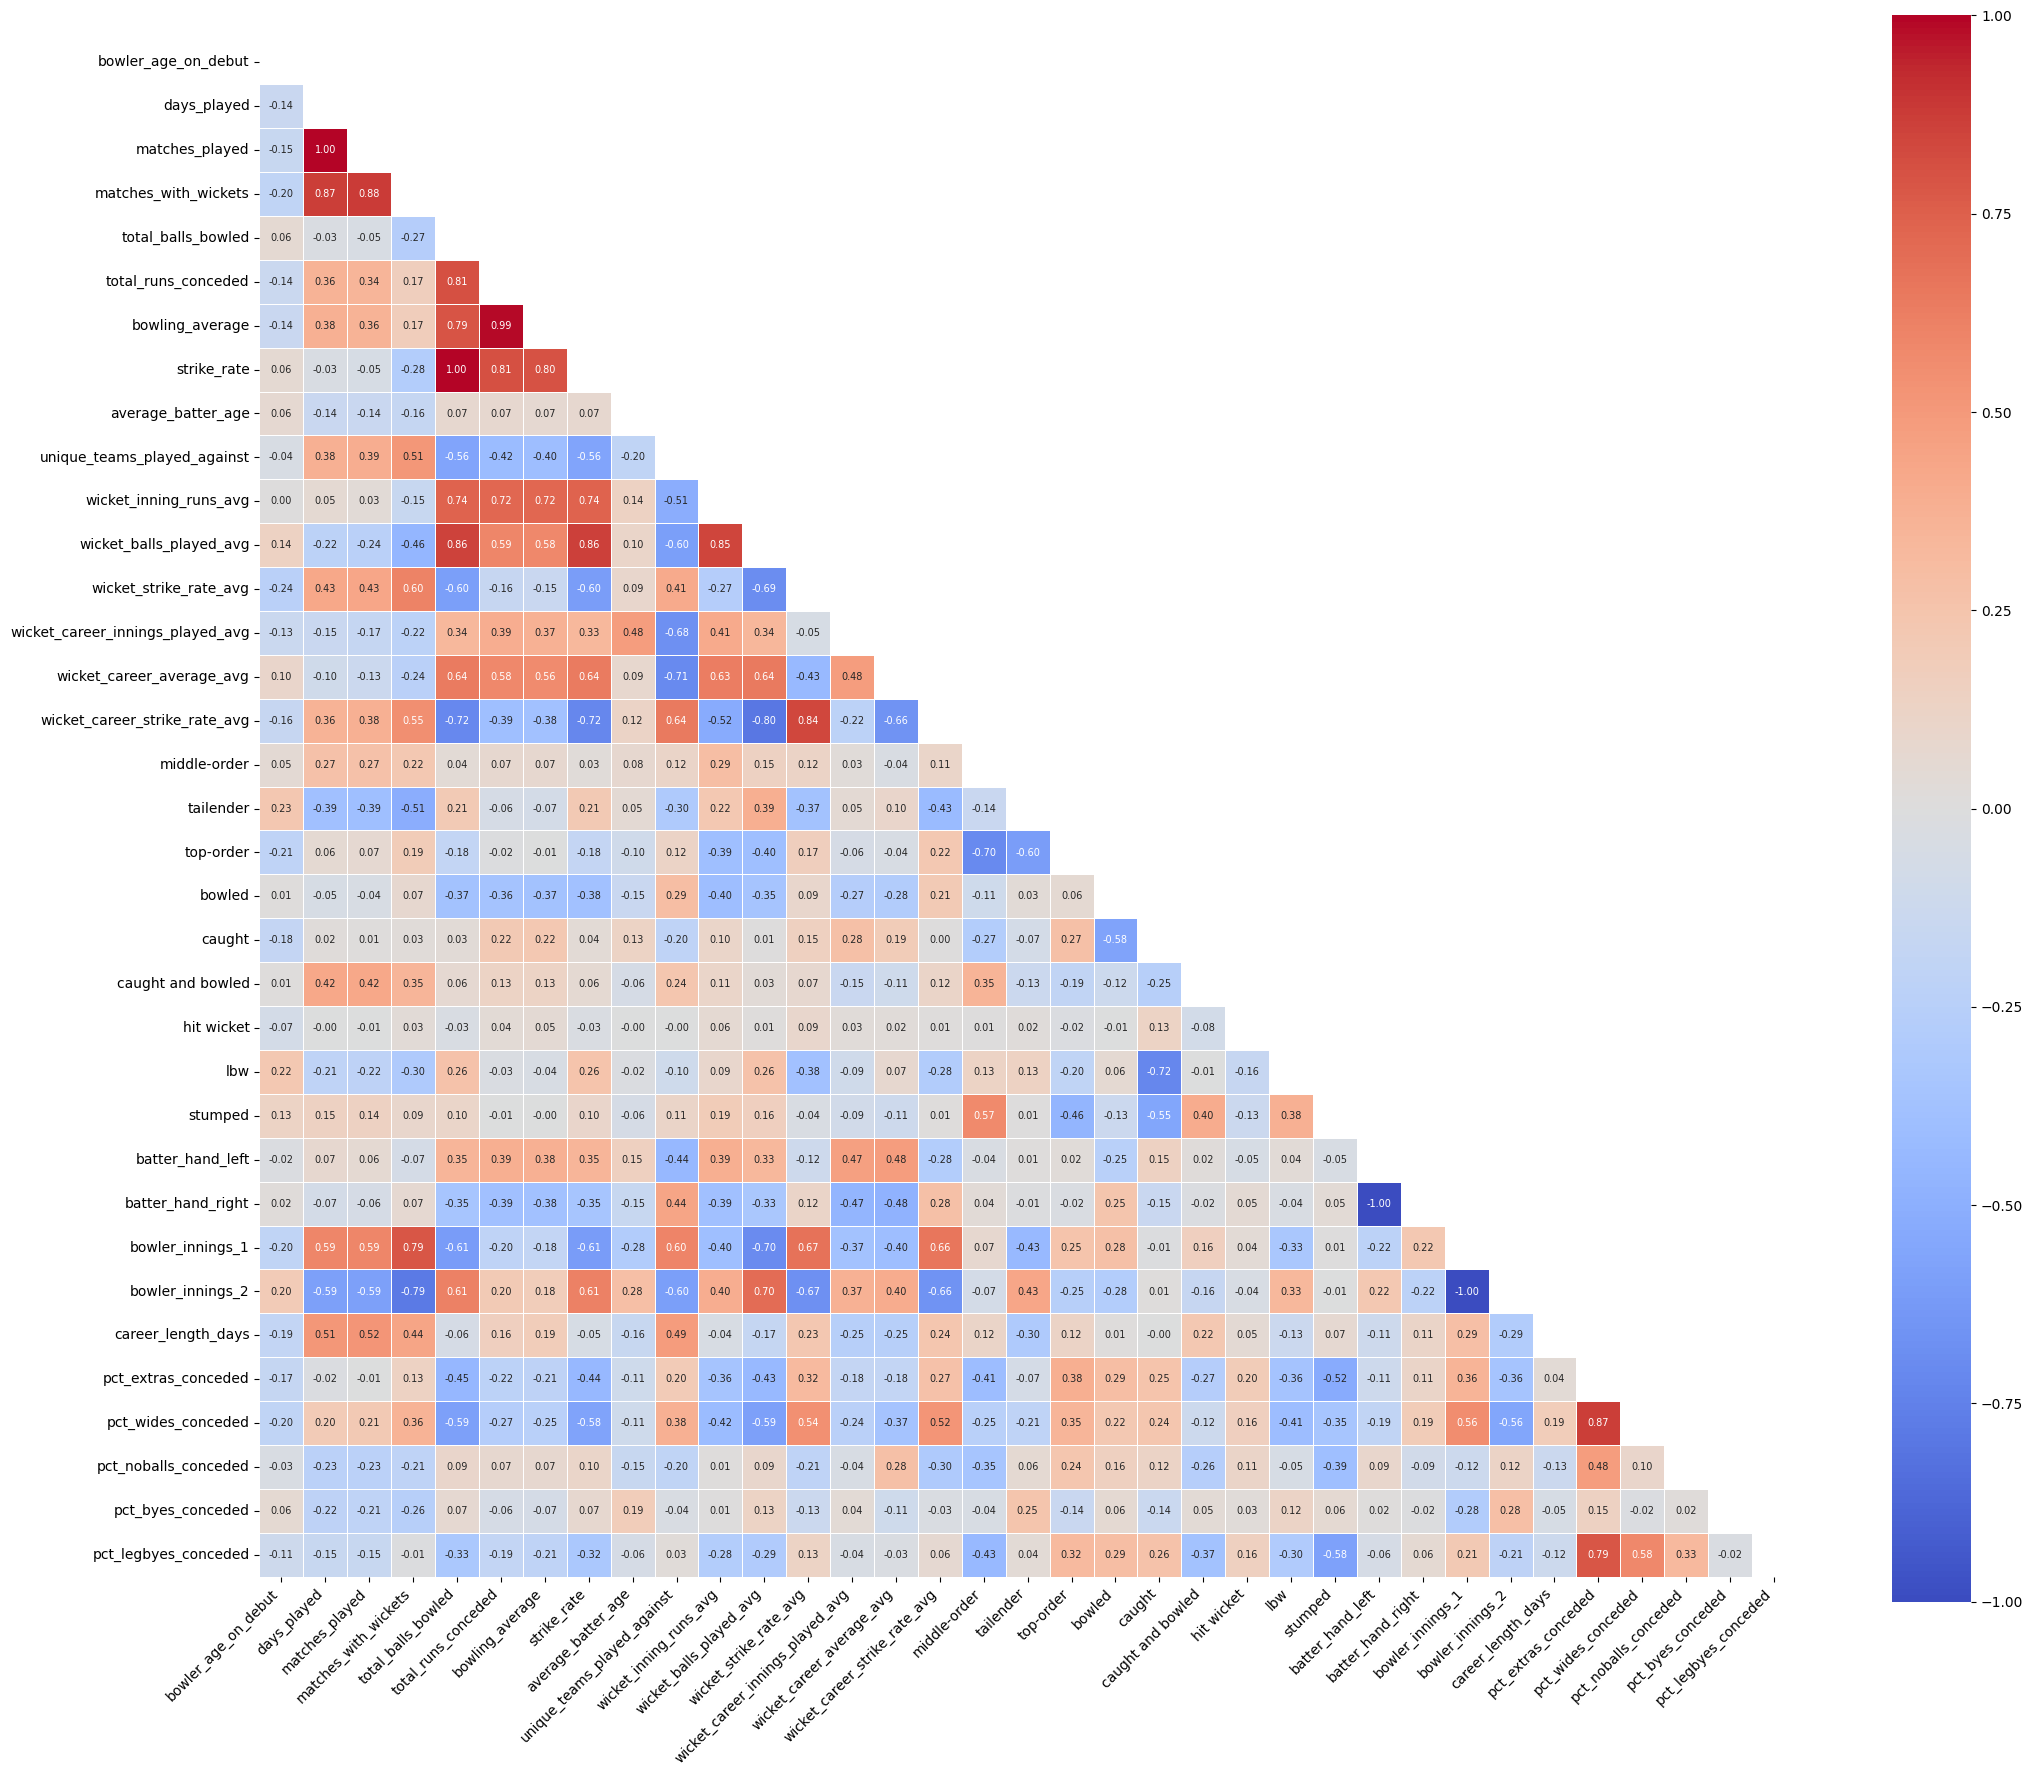

In [3]:
corr_df = analysis_data.drop(
    ['bowler_id', 'bowling_hand', 'bowling_type', 'bowler_batting_hand'], axis=1
).corr()

mask = np.triu(np.ones_like(corr_df, dtype=bool))

plt.figure(figsize=(22, 18))
sns.heatmap(
    corr_df,
    mask=mask,
    cmap='coolwarm',
    vmin=-1, vmax=1, center=0,
    annot=True,
    fmt='.2f',
    annot_kws={'size': 7},
    linewidths=0.5,
    square=True,
)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

In [4]:
high_corr = corr_df.where(mask == False).stack()
high_corr = high_corr[(high_corr.abs() > 0.8) & (high_corr.abs() < 1.0)].sort_values(ascending=False)
high_corr

matches_played                 days_played               0.998286
strike_rate                    total_balls_bowled        0.996981
bowling_average                total_runs_conceded       0.990875
matches_with_wickets           matches_played            0.877971
                               days_played               0.874523
pct_wides_conceded             pct_extras_conceded       0.874467
wicket_balls_played_avg        strike_rate               0.859650
                               total_balls_bowled        0.857885
                               wicket_inning_runs_avg    0.849034
wicket_career_strike_rate_avg  wicket_strike_rate_avg    0.839864
total_runs_conceded            total_balls_bowled        0.809894
strike_rate                    total_runs_conceded       0.806381
bowler_innings_2               bowler_innings_1         -1.000000
dtype: float64

1. Dropping days_played to keep matches_played
2. Dropping matches_with_wickets to keep matches_played
3. Dropping pct_extras_conceded to keep pct_wides_conceded (can do an analysis of type of extras separately and keep pct_extras_conceded, dropping the others)
4. Dropping total_runs_conceded to keep total_balls_bowled and use strike rate as proxy

In [5]:
corr_cols = ['days_played', 'matches_with_wickets', 'pct_extras_conceded', 'total_runs_conceded', 'total_balls_bowled']

analysis_data_copy = analysis_data.drop(columns=corr_cols)
print(analysis_data_copy.shape)
analysis_data_copy.head()

(306, 34)


,bowler_id,bowling_hand,bowling_type,bowler_batting_hand,bowler_age_on_debut,matches_played,bowling_average,strike_rate,average_batter_age,unique_teams_played_against,wicket_inning_runs_avg,wicket_balls_played_avg,wicket_strike_rate_avg,wicket_career_innings_played_avg,wicket_career_average_avg,wicket_career_strike_rate_avg,middle-order,tailender,top-order,bowled,caught,caught and bowled,hit wicket,lbw,stumped,batter_hand_left,batter_hand_right,bowler_innings_1,bowler_innings_2,career_length_days,pct_wides_conceded,pct_noballs_conceded,pct_byes_conceded,pct_legbyes_conceded
0,3086f7a4,left,orthodox,left,22,128,28.309859,31.669014,29.036691,17,21.346667,23.973856,95.054335,97.751634,28.798714,83.147698,0.478873,0.126761,0.394366,0.239437,0.507042,0.049296,0.0,0.161972,0.042254,0.295775,0.704225,0.922535,0.077465,3625,0.009784,0.000889,0.004003,0.009340
1,2af28253,left,orthodox,left,19,73,16.861111,20.527778,27.394415,21,15.510638,17.020000,86.129572,29.980000,22.215402,85.384524,0.500000,0.138889,0.361111,0.148148,0.574074,0.074074,0.0,0.111111,0.092593,0.126214,0.873786,1.000000,0.000000,1484,0.027064,0.000000,0.005413,0.005864
2,b410bd3d,right,legbreak googly,right,16,48,12.601852,16.916667,29.549457,21,15.713376,18.907738,71.703952,39.812500,24.877364,79.776408,0.518519,0.138889,0.342593,0.222222,0.472222,0.037037,0.0,0.185185,0.083333,0.211538,0.788462,1.000000,0.000000,1393,0.027367,0.000000,0.008758,0.010400
3,2b7609f1,left,orthodox,right,20,93,21.509259,28.185185,27.172072,25,12.865385,17.875000,75.178320,28.368750,22.210815,87.529930,0.527778,0.157407,0.314815,0.287037,0.462963,0.046296,0.0,0.120370,0.083333,0.110000,0.890000,1.000000,0.000000,3770,0.010184,0.000000,0.006570,0.005913
4,46a7ac78,left,medium,left,27,78,16.523364,19.495327,28.365990,22,12.590909,14.421488,75.485314,28.504132,21.556879,86.630914,0.439252,0.205607,0.355140,0.420561,0.411215,0.009346,0.0,0.158879,0.000000,0.202020,0.797980,1.000000,0.000000,2350,0.026366,0.001918,0.006232,0.017737


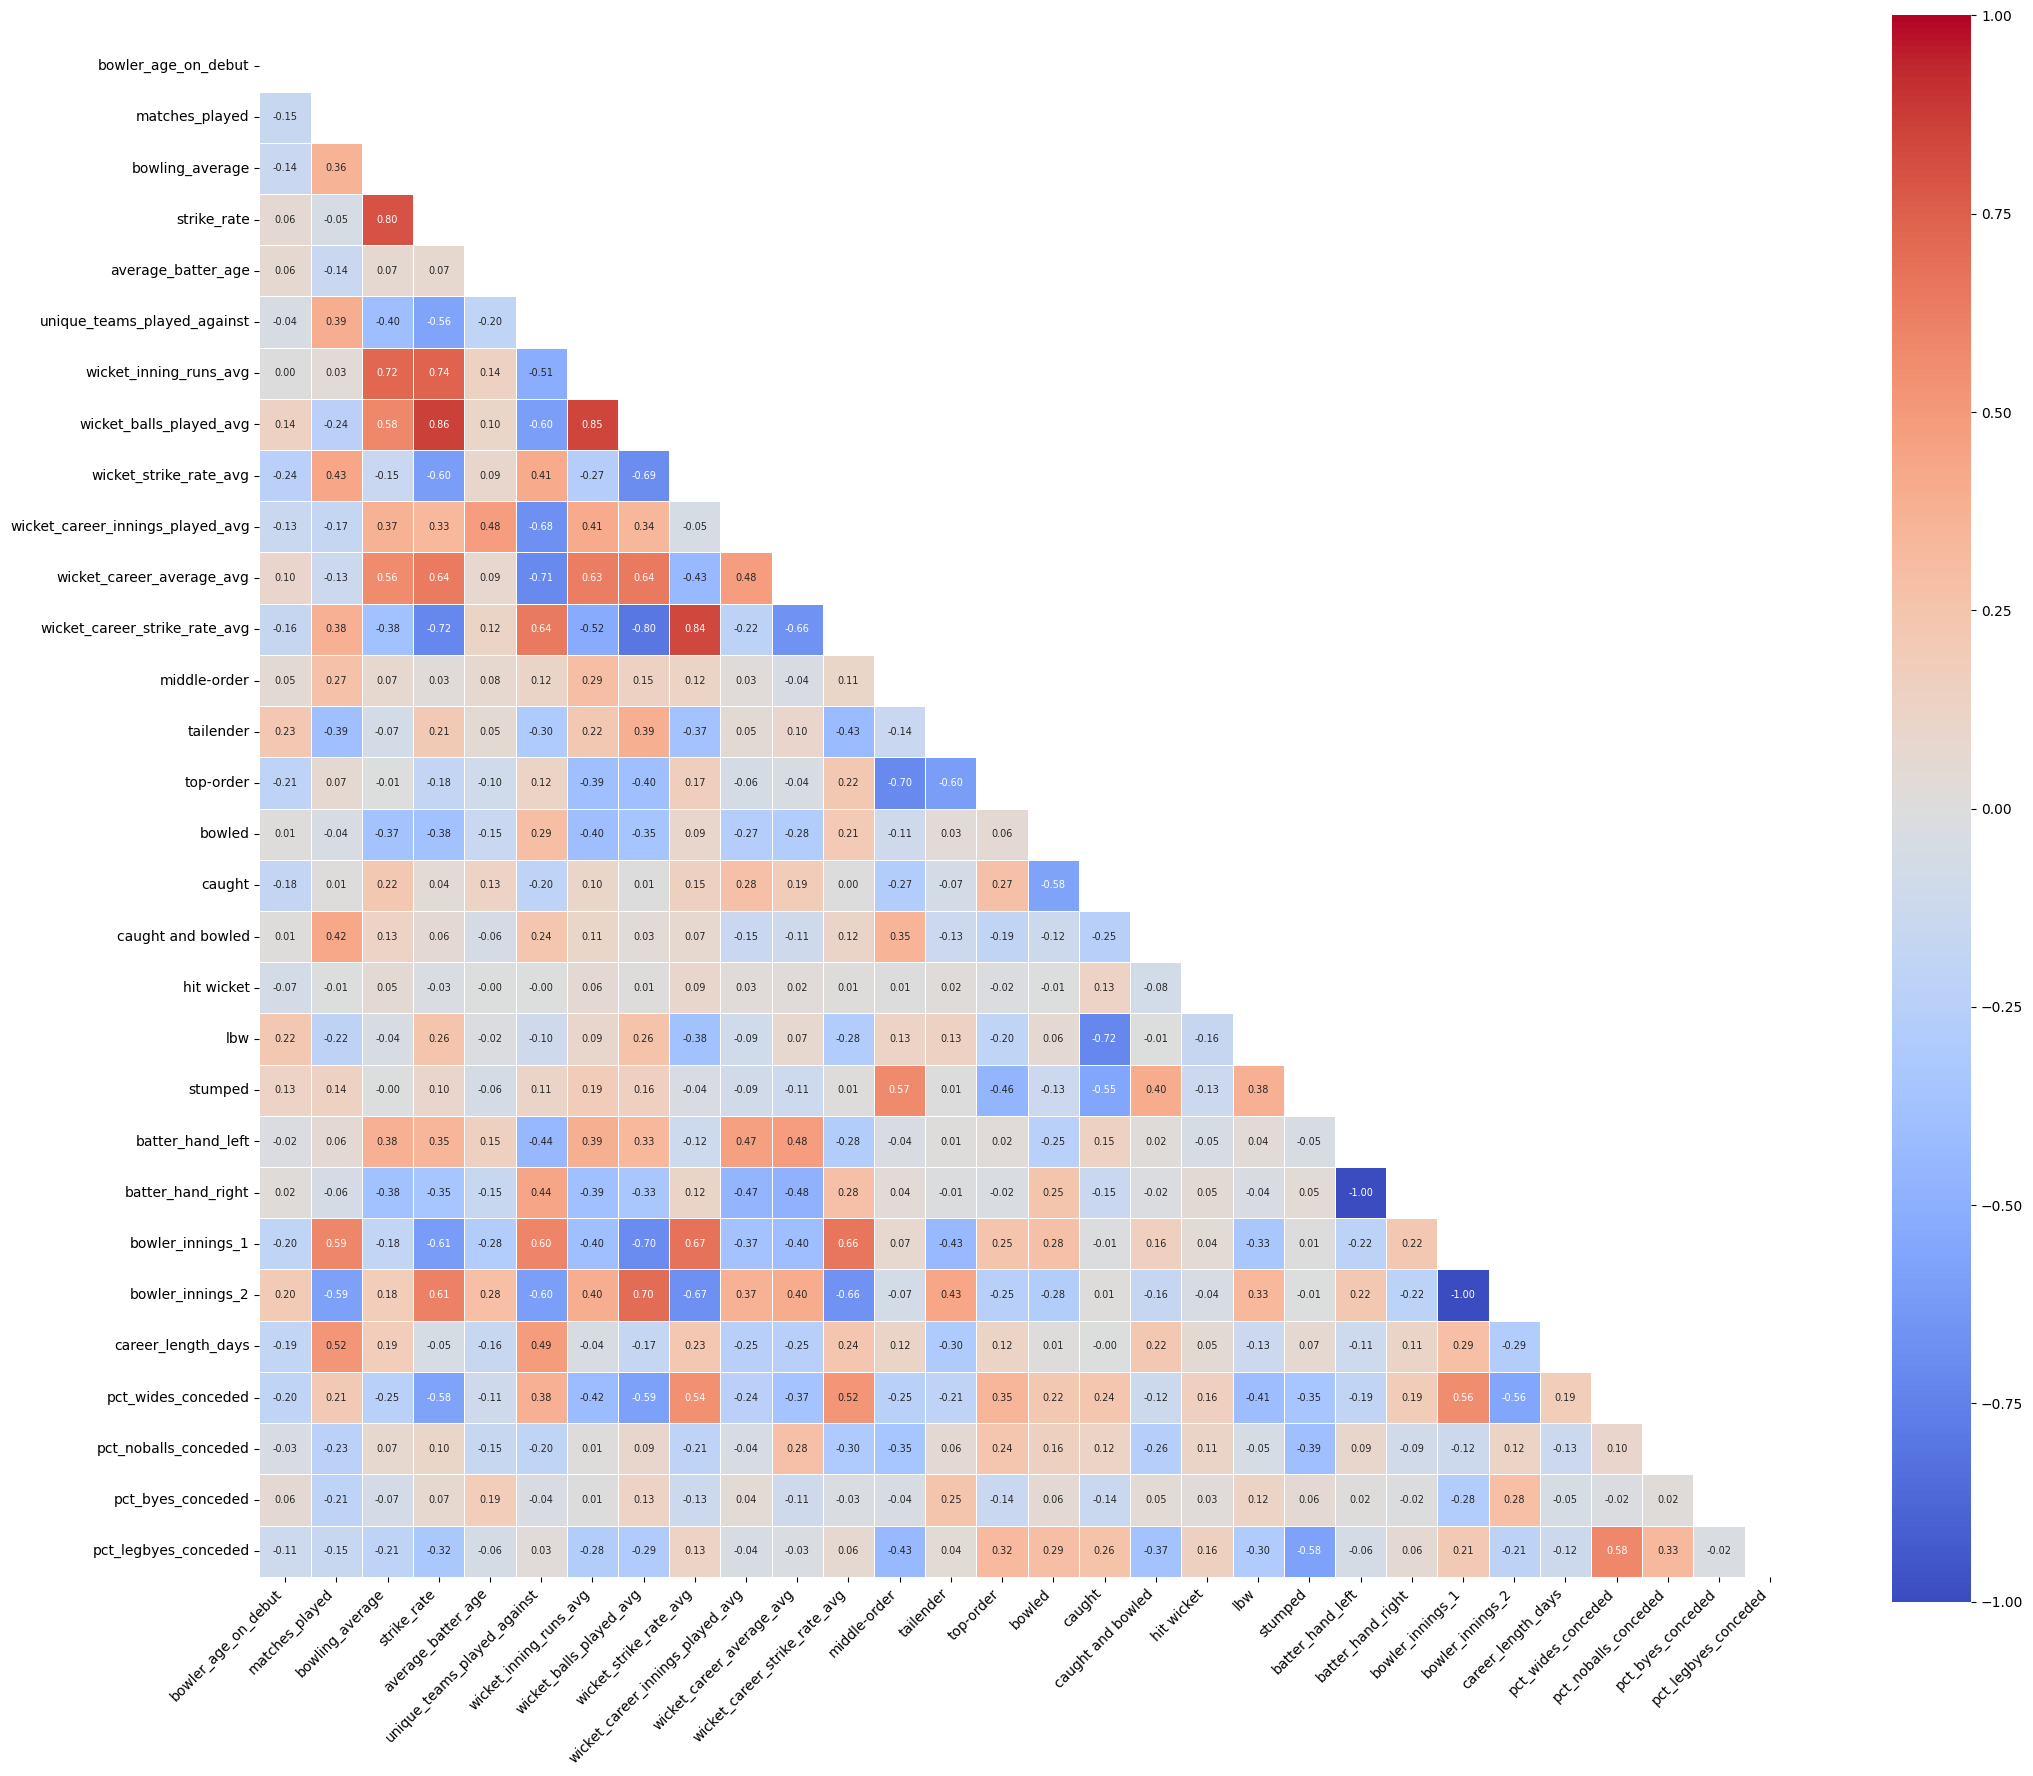

In [6]:
corr_df = analysis_data_copy.drop(
    ['bowler_id', 'bowling_hand', 'bowling_type', 'bowler_batting_hand'], axis=1
).corr()

mask = np.triu(np.ones_like(corr_df, dtype=bool))

plt.figure(figsize=(22, 18))
sns.heatmap(
    corr_df,
    mask=mask,
    cmap='coolwarm',
    vmin=-1, vmax=1, center=0,
    annot=True,
    fmt='.2f',
    annot_kws={'size': 7},
    linewidths=0.5,
    square=True,
)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

In [7]:
high_corr = corr_df.where(mask == False).stack()
high_corr = high_corr[(high_corr.abs() > 0.8) & (high_corr.abs() < 1.0)].sort_values(ascending=False)
high_corr

wicket_balls_played_avg        strike_rate               0.859650
                               wicket_inning_runs_avg    0.849034
wicket_career_strike_rate_avg  wicket_strike_rate_avg    0.839864
bowler_innings_2               bowler_innings_1         -1.000000
dtype: float64

In [123]:
analysis_data_copy.columns

Index(['bowler_id', 'bowling_hand', 'bowling_type', 'bowler_batting_hand',
       'bowler_age_on_debut', 'matches_played', 'bowling_average',
       'strike_rate', 'average_batter_age', 'unique_teams_played_against',
       'wicket_inning_runs_avg', 'wicket_balls_played_avg',
       'wicket_strike_rate_avg', 'wicket_career_innings_played_avg',
       'wicket_career_average_avg', 'wicket_career_strike_rate_avg',
       'middle-order', 'tailender', 'top-order', 'bowled', 'caught',
       'caught and bowled', 'hit wicket', 'lbw', 'stumped', 'batter_hand_left',
       'batter_hand_right', 'bowler_innings_1', 'bowler_innings_2',
       'career_length_days', 'pct_wides_conceded', 'pct_noballs_conceded',
       'pct_byes_conceded', 'pct_legbyes_conceded'],
      dtype='str')

/var/folders/z5/yxdlgv6930jbfdbkkddpr9ym0000gn/T/ipykernel_14564/1324871014.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/var/folders/z5/yxdlgv6930jbfdbkkddpr9ym0000gn/T/ipykernel_14564/1324871014.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/var/folders/z5/yxdlgv6930jbfdbkkddpr9ym0000gn/T/ipykernel_14564/1324871014.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


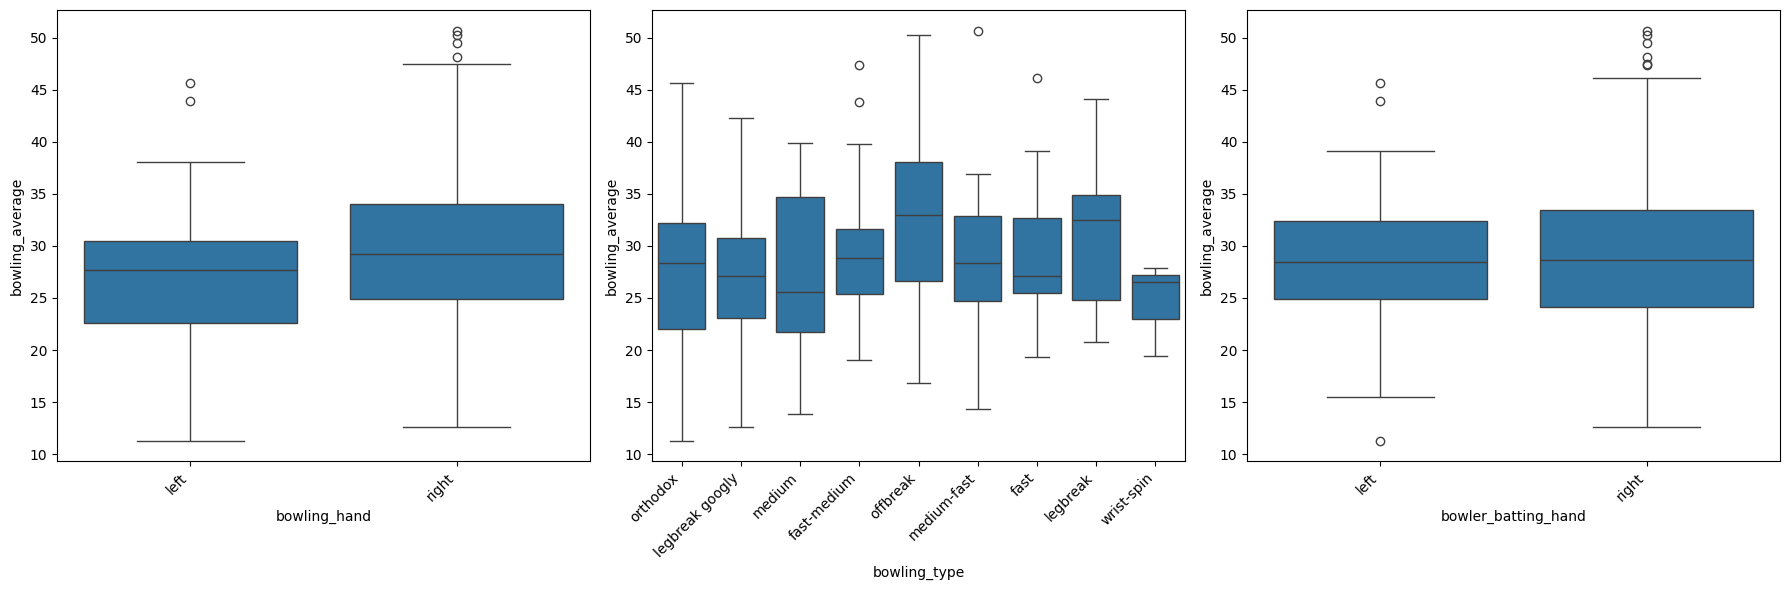

In [8]:
plt.figure(figsize=(18, 6))

ax1 = sns.boxplot(data=analysis_data_copy, x='bowling_hand', y='bowling_average', ax=plt.subplot(1, 3, 1))
ax2 = sns.boxplot(data=analysis_data_copy, x='bowling_type', y='bowling_average', ax=plt.subplot(1, 3, 2))
ax3 = sns.boxplot(data=analysis_data_copy, x='bowler_batting_hand', y='bowling_average', ax=plt.subplot(1, 3, 3))

for ax in [ax1, ax2, ax3]:
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

plt.tight_layout()

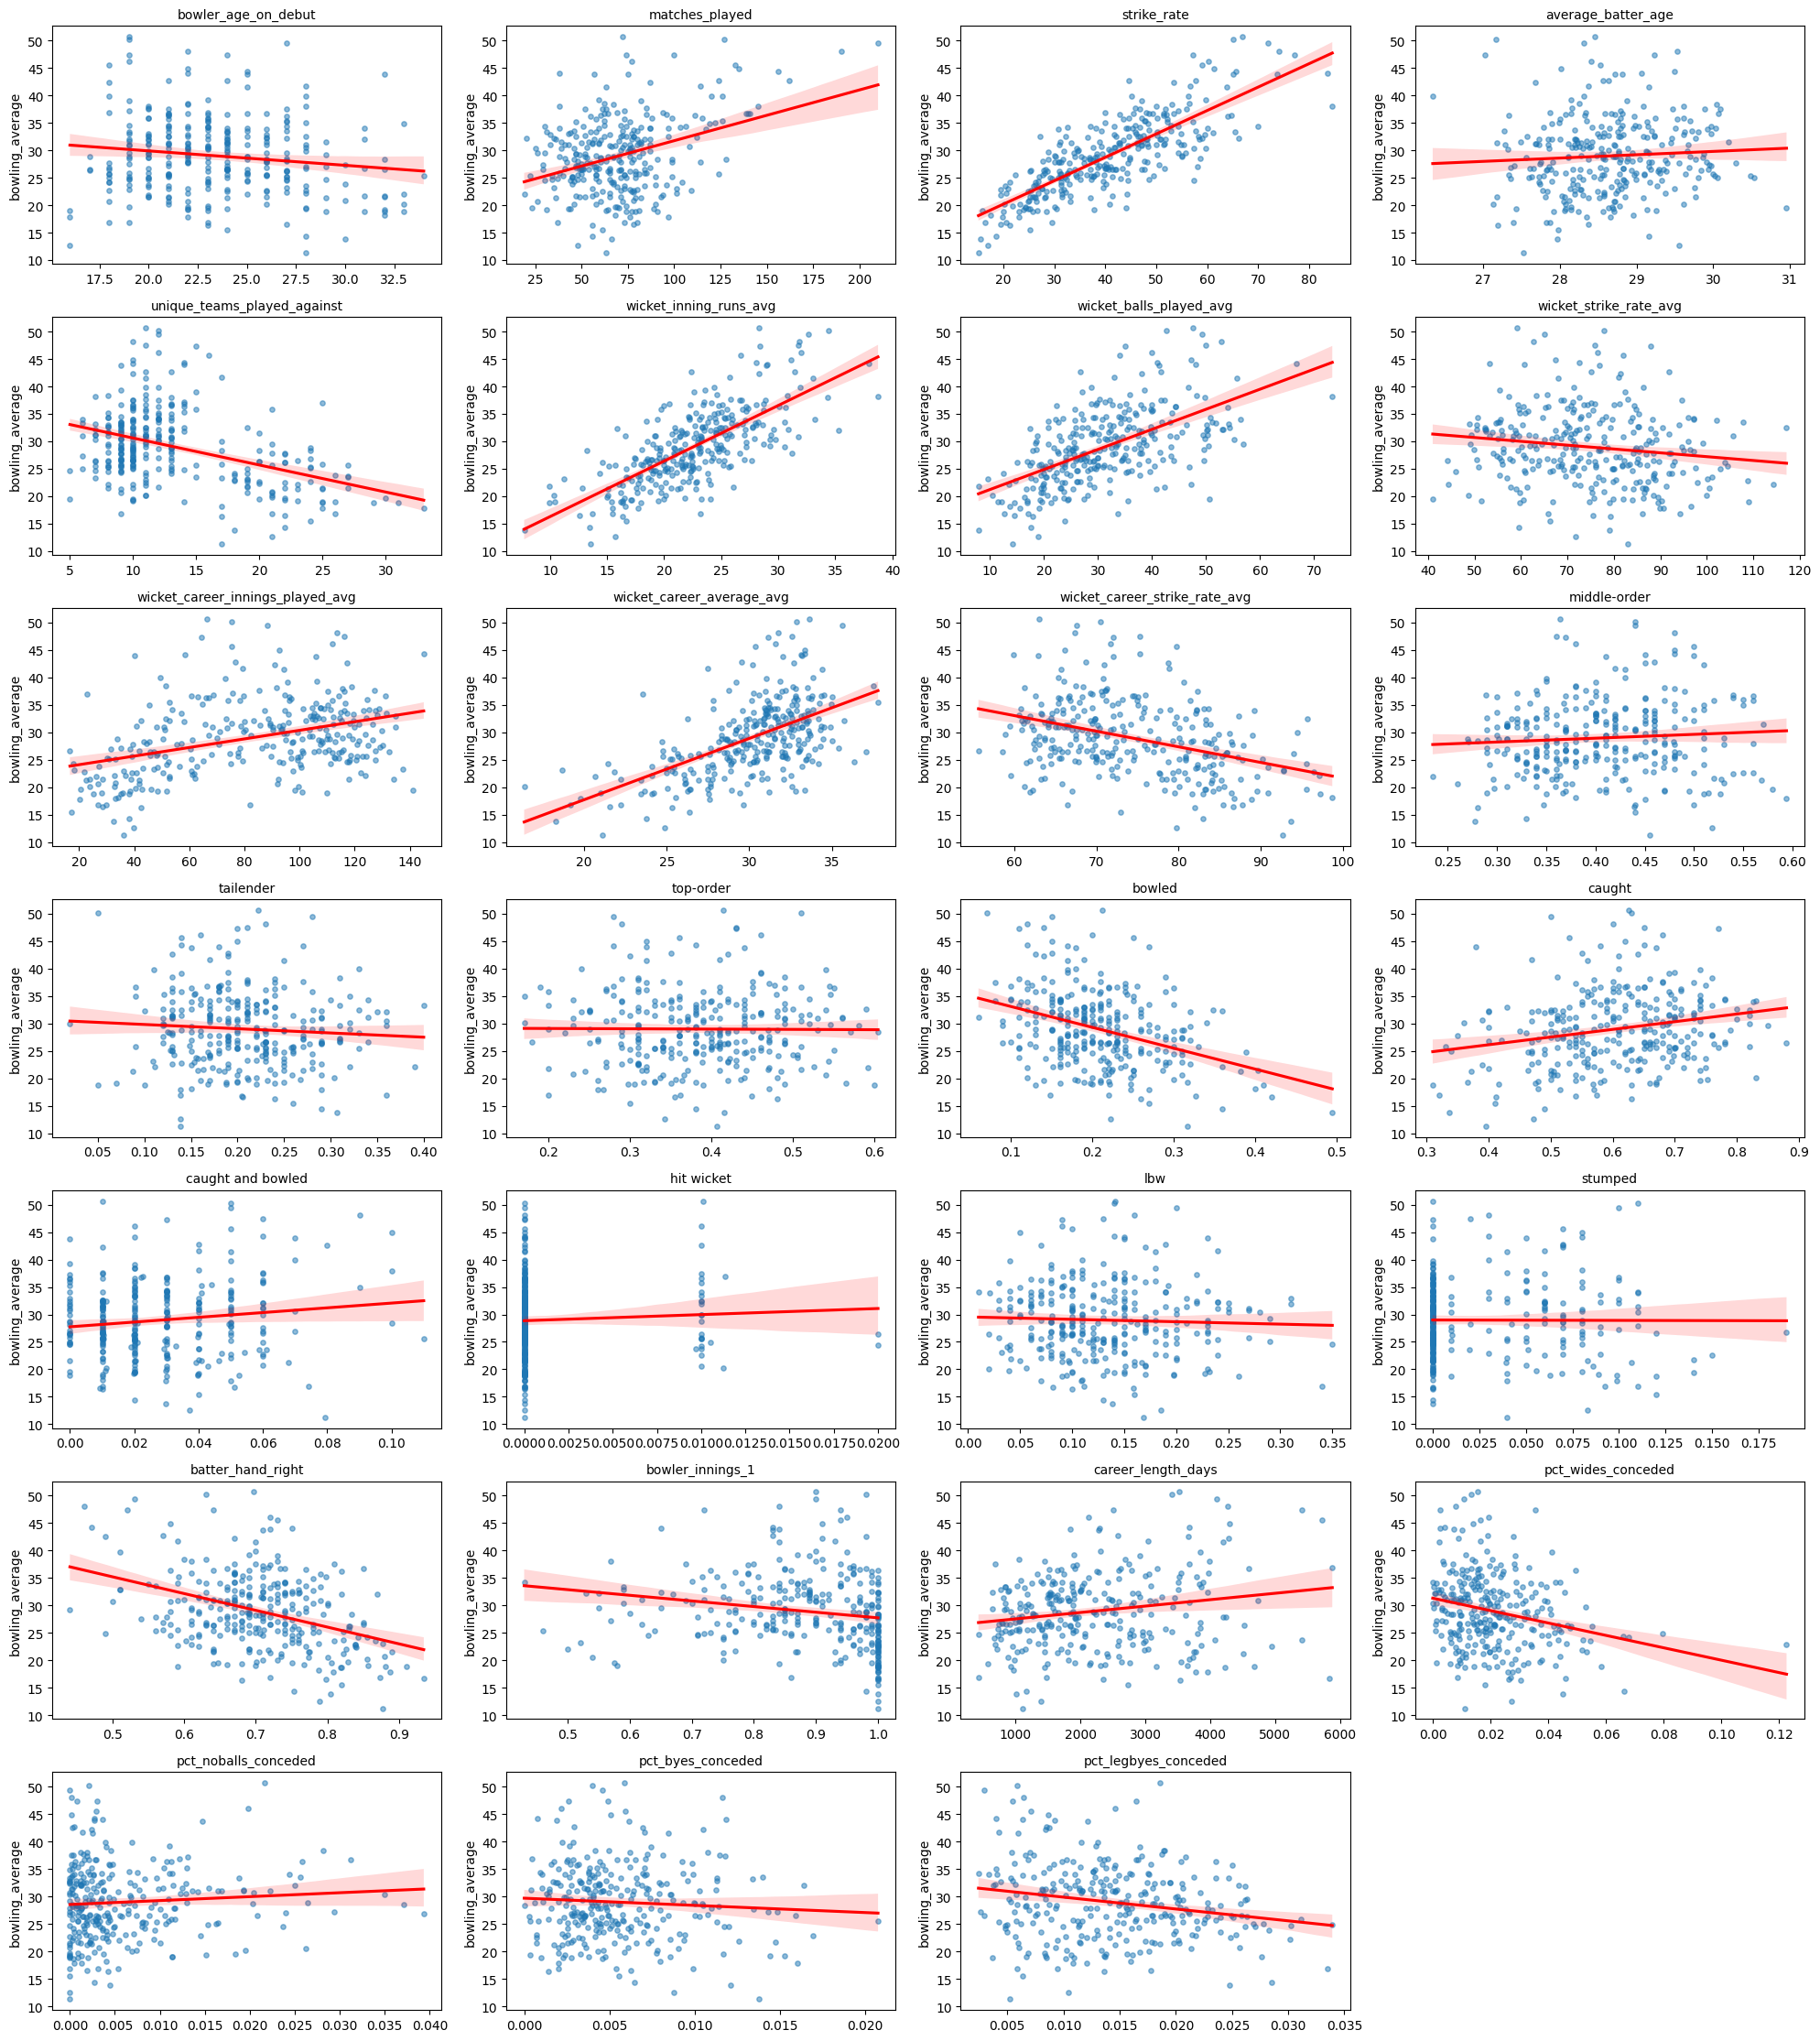

In [9]:
numeric_features = [
    'bowler_age_on_debut', 'matches_played', 'strike_rate', 'average_batter_age',
    'unique_teams_played_against', 'wicket_inning_runs_avg', 'wicket_balls_played_avg',
    'wicket_strike_rate_avg', 'wicket_career_innings_played_avg',
    'wicket_career_average_avg', 'wicket_career_strike_rate_avg',
    'middle-order', 'tailender', 'top-order', 'bowled', 'caught',
    'caught and bowled', 'hit wicket', 'lbw', 'stumped',
    'batter_hand_right', 'bowler_innings_1', 'career_length_days',
    'pct_wides_conceded', 'pct_noballs_conceded', 'pct_byes_conceded',
    'pct_legbyes_conceded',
]

ncols = 4
nrows = -(-len(numeric_features) // ncols)  # ceiling division

fig, axes = plt.subplots(nrows, ncols, figsize=(20, nrows * 3.2))
axes = axes.flatten()

for ax, feature in zip(axes, numeric_features):
    sns.regplot(data=analysis_data_copy, x=feature, y='bowling_average', ax=ax,
                scatter_kws={'alpha': 0.5, 's': 15}, line_kws={'color': 'red'})
    ax.set_title(feature, fontsize=10)
    ax.set_xlabel('')

for ax in axes[len(numeric_features):]:  # hide any unused slots (28th, if nrows*ncols > 27)
    ax.set_visible(False)

plt.tight_layout()